In [1]:
from pathlib import Path
print("Current working directory:")

print(Path.cwd())


Current working directory:
C:\Users\Maazuddin\GPT DS Project\notebooks
Current working directory:
C:\Users\Maazuddin\GPT DS Project\notebooks


In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/Users/Maazuddin/GPT DS Project/data/raw")

orders = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv"
)

items = pd.read_csv(
    DATA_DIR / "olist_order_items_dataset.csv"
)

print("Orders:", orders.shape)
print("Items:", items.shape)

Orders: (99441, 8)
Items: (112650, 7)
Orders: (99441, 8)
Items: (112650, 7)


In [3]:
print("Orders columns:")
print(orders.columns.tolist())

print("\nOrder Items columns:")
print(items.columns.tolist())

Orders columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Order Items columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Orders columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Order Items columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


In [4]:
print(
    "Duplicate order IDs in orders:",
    orders["order_id"].duplicated().sum()
)

print(
    "Duplicate order-item pairs in items:",
    items.duplicated(
        subset=["order_id", "order_item_id"]
    ).sum()
)

Duplicate order IDs in orders: 0
Duplicate order-item pairs in items: 0
Duplicate order IDs in orders: 0
Duplicate order-item pairs in items: 0


In [5]:
print("Missing values in orders:")
print(orders.isnull().sum())

print("\nMissing values in items:")
print(items.isnull().sum())

Missing values in orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing values in items:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Missing values in orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing values in items:
order_id               0
order_item_id          0
product_id             0

In [6]:
orders.groupby("order_status").agg(
    total_orders=("order_id", "size"),
    missing_approval=("order_approved_at", lambda s: s.isna().sum()),
    missing_carrier_date=("order_delivered_carrier_date", lambda s: s.isna().sum()),
    missing_delivery_date=("order_delivered_customer_date", lambda s: s.isna().sum())
)

,total_orders,missing_approval,missing_carrier_date,missing_delivery_date
order_status,,,,
approved,2,0,2,2
canceled,625,141,550,619
created,5,5,5,5
delivered,96478,14,2,8
invoiced,314,0,314,314
processing,301,0,301,301
shipped,1107,0,0,1107
unavailable,609,0,609,609


,total_orders,missing_approval,missing_carrier_date,missing_delivery_date
order_status,,,,
approved,2,0,2,2
canceled,625,141,550,619
created,5,5,5,5
delivered,96478,14,2,8
invoiced,314,0,314,314
processing,301,0,301,301
shipped,1107,0,0,1107
unavailable,609,0,609,609


In [7]:
delivered = orders[
    orders["order_status"] == "delivered"
]

print("Delivered orders:", len(delivered))

print(
    "Missing actual delivery date:",
    delivered["order_delivered_customer_date"].isna().sum()
)

print(
    "Missing promised delivery date:",
    delivered["order_estimated_delivery_date"].isna().sum()
)

Delivered orders: 96478
Missing actual delivery date: 8
Missing promised delivery date: 0
Delivered orders: 96478
Missing actual delivery date: 8
Missing promised delivery date: 0


In [8]:
eligible_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna())
].copy()

print("Eligible orders:", len(eligible_orders))
print(
    "Missing actual delivery dates:",
    eligible_orders["order_delivered_customer_date"].isna().sum()
)

Eligible orders: 96470
Missing actual delivery dates: 0
Eligible orders: 96470
Missing actual delivery dates: 0


In [9]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    eligible_orders[col] = pd.to_datetime(
        eligible_orders[col],
        errors="coerce"
    )

print(eligible_orders[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [10]:
eligible_orders["late_delivery"] = (
    eligible_orders["order_delivered_customer_date"].dt.normalize() # .dt.normalize() It removes the time portion and compares only the calendar dates
    >
    eligible_orders["order_estimated_delivery_date"].dt.normalize()
).astype("int8")

print(eligible_orders["late_delivery"].value_counts())

late_delivery
0    89936
1     6534
Name: count, dtype: int64
late_delivery
0    89936
1     6534
Name: count, dtype: int64


In [11]:
target_counts = eligible_orders["late_delivery"].value_counts()

target_percentages = (
    eligible_orders["late_delivery"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Target distribution:")
print(
    pd.DataFrame({
        "Order Count": target_counts,
        "Percentage (%)": target_percentages
    })
)

Target distribution:
               Order Count  Percentage (%)
late_delivery                             
0                    89936           93.23
1                     6534            6.77
Target distribution:
               Order Count  Percentage (%)
late_delivery                             
0                    89936           93.23
1                     6534            6.77


In [12]:
print("Missing target values:", eligible_orders["late_delivery"].isna().sum())

print("Unique target values:", sorted(eligible_orders["late_delivery"].unique()))

print("Total orders:", len(eligible_orders))

print(
    "Target counts add up:",
    eligible_orders["late_delivery"].value_counts().sum() == len(eligible_orders)
)

Missing target values: 0
Unique target values: [np.int8(0), np.int8(1)]
Total orders: 96470
Target counts add up: True
Missing target values: 0
Unique target values: [np.int8(0), np.int8(1)]
Total orders: 96470
Target counts add up: True


In [13]:
eligible_orders["delivery_delay_days"] = (
    eligible_orders["order_delivered_customer_date"].dt.normalize()
    - eligible_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

print(
    eligible_orders["delivery_delay_days"].describe().round(2)
)

count    96470.00
mean       -11.88
std         10.18
min       -147.00
25%        -17.00
50%        -12.00
75%         -7.00
max        188.00
Name: delivery_delay_days, dtype: float64
count    96470.00
mean       -11.88
std         10.18
min       -147.00
25%        -17.00
50%        -12.00
75%         -7.00
max        188.00
Name: delivery_delay_days, dtype: float64


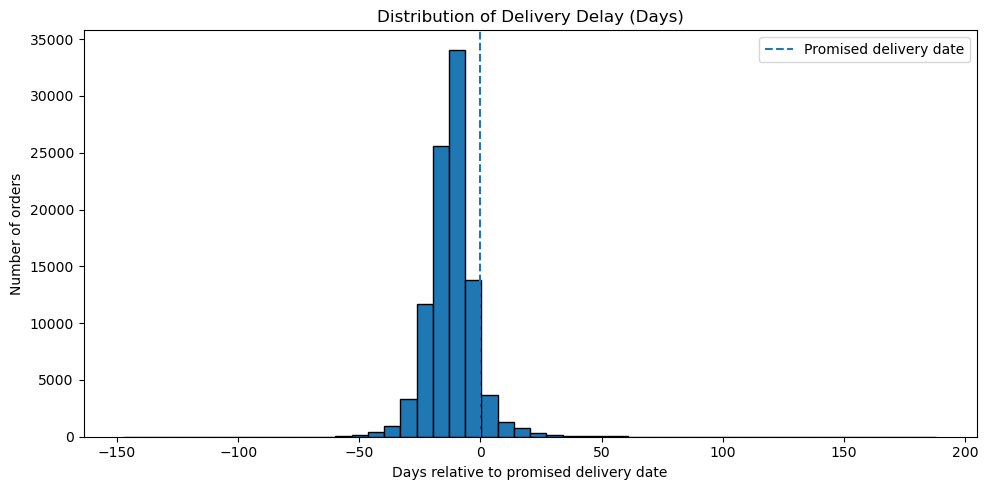

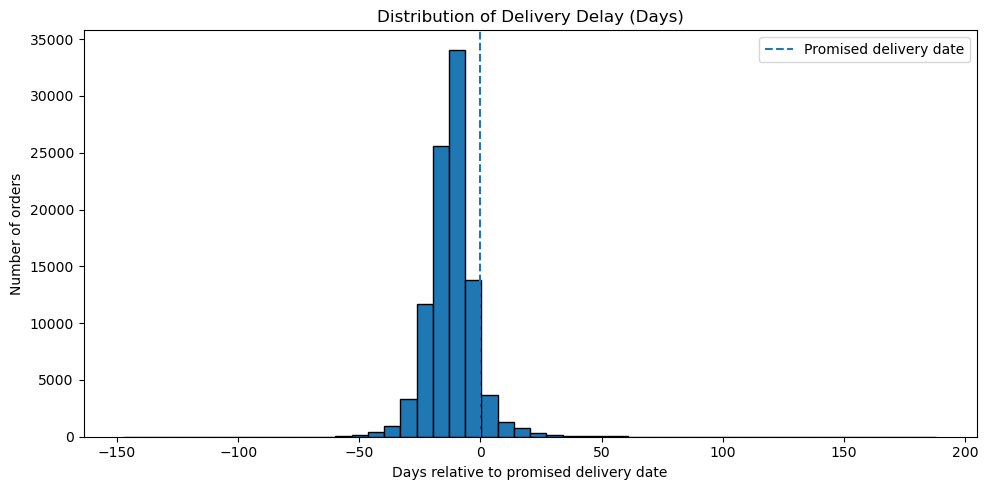

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    eligible_orders["delivery_delay_days"],
    bins=50,
    edgecolor="black"
)

plt.axvline(0, linestyle="--", label="Promised delivery date")

plt.title("Distribution of Delivery Delay (Days)")
plt.xlabel("Days relative to promised delivery date")
plt.ylabel("Number of orders")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
eligible_orders.nlargest(
    5, "delivery_delay_days"
)[[
    "order_id",
    "order_status",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "delivery_delay_days"
]]

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,188
19590,ca07593549f1816d26a572e06dc1eab6,delivered,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,181
11399,47b40429ed8cce3aee9199792275433f,delivered,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,175
81401,2fe324febf907e3ea3f2aa9650869fa5,delivered,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,167
89130,285ab9426d6982034523a855f55a885e,delivered,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,166


,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,188
19590,ca07593549f1816d26a572e06dc1eab6,delivered,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,181
11399,47b40429ed8cce3aee9199792275433f,delivered,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,175
81401,2fe324febf907e3ea3f2aa9650869fa5,delivered,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,167
89130,285ab9426d6982034523a855f55a885e,delivered,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,166


In [16]:
extreme_orders = eligible_orders.nlargest(
    5, "delivery_delay_days"
)

print(
    extreme_orders[[
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_delay_days"
    ]].to_string(index=False)
)

                        order_id order_purchase_timestamp order_delivered_customer_date order_estimated_delivery_date  delivery_delay_days
1b3190b2dfa9d789e1f14c05b647a14a      2018-02-23 14:57:35           2018-09-19 23:24:07                    2018-03-15                  188
ca07593549f1816d26a572e06dc1eab6      2017-02-21 23:31:27           2017-09-19 14:36:39                    2017-03-22                  181
47b40429ed8cce3aee9199792275433f      2018-01-03 09:44:01           2018-07-13 20:51:31                    2018-01-19                  175
2fe324febf907e3ea3f2aa9650869fa5      2017-03-13 20:17:10           2017-09-19 17:00:07                    2017-04-05                  167
285ab9426d6982034523a855f55a885e      2017-03-08 22:47:40           2017-09-19 14:00:04                    2017-04-06                  166
                        order_id order_purchase_timestamp order_delivered_customer_date order_estimated_delivery_date  delivery_delay_days
1b3190b2dfa9d789e1f14c05b64

In [17]:
eligible_orders["promised_delivery_days"] = (
    eligible_orders["order_estimated_delivery_date"].dt.normalize()
    - eligible_orders["order_purchase_timestamp"].dt.normalize()
).dt.days

print(
    eligible_orders["promised_delivery_days"].describe().round(2)
)

count    96470.00
mean        24.37
std          8.76
min          3.00
25%         19.00
50%         24.00
75%         29.00
max        156.00
Name: promised_delivery_days, dtype: float64
count    96470.00
mean        24.37
std          8.76
min          3.00
25%         19.00
50%         24.00
75%         29.00
max        156.00
Name: promised_delivery_days, dtype: float64


In [18]:
eligible_orders.nlargest(
    5, "promised_delivery_days"
)[[
    "order_id",
    "order_purchase_timestamp",
    "order_estimated_delivery_date",
    "order_delivered_customer_date",
    "promised_delivery_days",
    "delivery_delay_days"
]]

,order_id,order_purchase_timestamp,order_estimated_delivery_date,order_delivered_customer_date,promised_delivery_days,delivery_delay_days
57160,eec7f369423b033e549c02f3c5381205,2018-02-06 20:44:56,2018-07-12,2018-02-27 16:35:43,156,-135
40094,0607f0efea4b566f1eb8f7d3c2397320,2018-03-06 09:47:07,2018-08-03,2018-03-09 23:36:47,150,-147
15791,c72727d29cde4cf870d569bf65edabfd,2017-02-07 18:01:15,2017-07-04,2017-02-14 14:27:45,147,-140
86444,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:36,2017-10-11,2017-06-09 13:35:54,141,-124
67488,40dc2ba6f322a17626aac6244332828c,2017-10-05 21:39:05,2018-01-30,2017-10-13 13:49:07,117,-109


,order_id,order_purchase_timestamp,order_estimated_delivery_date,order_delivered_customer_date,promised_delivery_days,delivery_delay_days
57160,eec7f369423b033e549c02f3c5381205,2018-02-06 20:44:56,2018-07-12,2018-02-27 16:35:43,156,-135
40094,0607f0efea4b566f1eb8f7d3c2397320,2018-03-06 09:47:07,2018-08-03,2018-03-09 23:36:47,150,-147
15791,c72727d29cde4cf870d569bf65edabfd,2017-02-07 18:01:15,2017-07-04,2017-02-14 14:27:45,147,-140
86444,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:36,2017-10-11,2017-06-09 13:35:54,141,-124
67488,40dc2ba6f322a17626aac6244332828c,2017-10-05 21:39:05,2018-01-30,2017-10-13 13:49:07,117,-109


In [19]:
print(eligible_orders.columns.tolist())

print(
    eligible_orders.nlargest(5, "promised_delivery_days")[
        ["order_id", "promised_delivery_days", "delivery_delay_days"]
    ].to_dict("records")
)

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'late_delivery', 'delivery_delay_days', 'promised_delivery_days']
[{'order_id': 'eec7f369423b033e549c02f3c5381205', 'promised_delivery_days': 156, 'delivery_delay_days': -135}, {'order_id': '0607f0efea4b566f1eb8f7d3c2397320', 'promised_delivery_days': 150, 'delivery_delay_days': -147}, {'order_id': 'c72727d29cde4cf870d569bf65edabfd', 'promised_delivery_days': 147, 'delivery_delay_days': -140}, {'order_id': 'c2bb89b5c1dd978d507284be78a04cb2', 'promised_delivery_days': 141, 'delivery_delay_days': -124}, {'order_id': '40dc2ba6f322a17626aac6244332828c', 'promised_delivery_days': 117, 'delivery_delay_days': -109}]
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', '

In [20]:
long_windows = eligible_orders[
    eligible_orders["promised_delivery_days"] > 60
]

print("Orders with promised windows over 60 days:", len(long_windows))
print(
    "Percentage of eligible orders:",
    round(len(long_windows) / len(eligible_orders) * 100, 2),
    "%"
)

Orders with promised windows over 60 days: 236
Percentage of eligible orders: 0.24 %
Orders with promised windows over 60 days: 236
Percentage of eligible orders: 0.24 %


In [21]:
eligible_orders.groupby("late_delivery")[
    "delivery_delay_days"
].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
late_delivery,,,,,,,,
0,89936.0,-13.51,7.50,-147.0,-17.0,-13.0,-8.0,0.0
1,6534.0,10.62,14.64,1.0,3.0,7.0,13.0,188.0


,count,mean,std,min,25%,50%,75%,max
late_delivery,,,,,,,,
0,89936.0,-13.51,7.50,-147.0,-17.0,-13.0,-8.0,0.0
1,6534.0,10.62,14.64,1.0,3.0,7.0,13.0,188.0


In [22]:
print("Available columns:")
for col in eligible_orders.columns:
    print("-", col)

Available columns:
- order_id
- customer_id
- order_status
- order_purchase_timestamp
- order_approved_at
- order_delivered_carrier_date
- order_delivered_customer_date
- order_estimated_delivery_date
- late_delivery
- delivery_delay_days
- promised_delivery_days
Available columns:
- order_id
- customer_id
- order_status
- order_purchase_timestamp
- order_approved_at
- order_delivered_carrier_date
- order_delivered_customer_date
- order_estimated_delivery_date
- late_delivery
- delivery_delay_days
- promised_delivery_days


Here's our initial feature-selection plan:
Column	                        Decision	        Reason
order_id	                    Exclude	    Identifier, not a useful predictive feature by itself
customer_id	                    Exclude     initially	High-cardinality identifier
order_status	                Exclude	    Can reveal information about the outcome
order_purchase_timestamp	    Keep and transform	Can derive purchase day, month, hour
order_approved_at	            Potentially keep	Available only if prediction happens after approval
order_delivered_carrier_date	Exclude	    Happens after the intended prediction time
order_delivered_customer_date	Exclude	    Used to determine the target
order_estimated_delivery_date	Potentially keep	Must be available at prediction time
late_delivery	                Target      only	What we're predicting
delivery_delay_days	            Exclude	    Directly derived from the actual outcome
promised_delivery_days	        Potentially keep	Derived from purchase and promised dates

In [23]:
print("Items dataset shape:", items.shape)
print("\nColumns:")
print(items.columns.tolist())

print("\nFirst 5 rows:")
display(items.head())

Items dataset shape: (112650, 7)

Columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

First 5 rows:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


Items dataset shape: (112650, 7)

Columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

First 5 rows:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [24]:
items_per_order = items.groupby("order_id").size()

print("Orders with item records:", len(items_per_order))
print("\nItems per order:")
print(items_per_order.describe().round(2))



Orders with item records: 98666

Items per order:
count    98666.00
mean         1.14
std          0.54
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         21.00
dtype: float64
Orders with item records: 98666

Items per order:
count    98666.00
mean         1.14
std          0.54
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         21.00
dtype: float64


In [25]:
order_features = items.groupby("order_id").agg(
    total_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    seller_count=("seller_id", "nunique")
).reset_index()

print("Rows in order_features:", len(order_features))
display(order_features.head())

Rows in order_features: 98666


,order_id,total_items,total_price,total_freight,seller_count
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,1


Rows in order_features: 98666


,order_id,total_items,total_price,total_freight,seller_count
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,1


In [26]:
print(
    "Duplicate order IDs:",
    order_features["order_id"].duplicated().sum()
)

print(
    "Missing values:",
    order_features.isna().sum().to_dict()
)

Duplicate order IDs: 0
Missing values: {'order_id': 0, 'total_items': 0, 'total_price': 0, 'total_freight': 0, 'seller_count': 0}
Duplicate order IDs: 0
Missing values: {'order_id': 0, 'total_items': 0, 'total_price': 0, 'total_freight': 0, 'seller_count': 0}


In [27]:
model_data = eligible_orders.merge(
    order_features,
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Merged dataset shape:", model_data.shape)
print("\nMerge status:")
print(model_data["_merge"].value_counts())

Merged dataset shape: (96470, 16)

Merge status:
_merge
both          96470
left_only         0
right_only        0
Name: count, dtype: int64
Merged dataset shape: (96470, 16)

Merge status:
_merge
both          96470
left_only         0
right_only        0
Name: count, dtype: int64


In [28]:
print("Dataset shape:", model_data.shape)

print("\nTarget distribution:")
print(
    model_data["late_delivery"]
    .value_counts()
    .sort_index()
)

print("\nNew feature columns:")
print(
    model_data[
        ["total_items", "total_price", "total_freight", "seller_count"]
    ].describe().round(2)
)


Dataset shape: (96470, 16)

Target distribution:
late_delivery
0    89936
1     6534
Name: count, dtype: int64

New feature columns:
       total_items  total_price  total_freight  seller_count
count     96470.00     96470.00       96470.00      96470.00
mean          1.14       137.04          22.79          1.01
std           0.54       209.05          21.56          0.12
min           1.00         0.85           0.00          1.00
25%           1.00        45.90          13.85          1.00
50%           1.00        86.50          17.17          1.00
75%           1.00       149.90          24.02          1.00
max          21.00     13440.00        1794.96          5.00
Dataset shape: (96470, 16)

Target distribution:
late_delivery
0    89936
1     6534
Name: count, dtype: int64

New feature columns:
       total_items  total_price  total_freight  seller_count
count     96470.00     96470.00       96470.00      96470.00
mean          1.14       137.04          22.79          1.01
st

In [29]:
item_delay_summary = model_data.groupby("total_items").agg(
    order_count=("late_delivery", "size"),
    late_orders=("late_delivery", "sum"),
    late_rate=("late_delivery", "mean")
)

item_delay_summary["late_rate"] = (
    item_delay_summary["late_rate"] * 100
).round(2)

display(item_delay_summary)

,order_count,late_orders,late_rate
total_items,,,
1,86835,6024,6.94
2,7392,397,5.37
3,1306,64,4.90
4,495,23,4.65
5,193,9,4.66
6,191,16,8.38
7,22,0,0.00
8,8,0,0.00
9,3,0,0.00


,order_count,late_orders,late_rate
total_items,,,
1,86835,6024,6.94
2,7392,397,5.37
3,1306,64,4.90
4,495,23,4.65
5,193,9,4.66
6,191,16,8.38
7,22,0,0.00
8,8,0,0.00
9,3,0,0.00


In [30]:
model_data["item_group"] = pd.cut(
    model_data["total_items"],
    bins=[0, 1, 2, 5, float("inf")],
    labels=["1 item", "2 items", "3–5 items", "6+ items"]
)

item_group_summary = model_data.groupby(
    "item_group", observed=False
).agg(
    order_count=("late_delivery", "size"),
    late_orders=("late_delivery", "sum"),
    late_rate=("late_delivery", "mean")
)

item_group_summary["late_rate"] = (
    item_group_summary["late_rate"] * 100
).round(2)

display(item_group_summary)

,order_count,late_orders,late_rate
item_group,,,
1 item,86835,6024,6.94
2 items,7392,397,5.37
3–5 items,1994,96,4.81
6+ items,249,17,6.83


,order_count,late_orders,late_rate
item_group,,,
1 item,86835,6024,6.94
2 items,7392,397,5.37
3–5 items,1994,96,4.81
6+ items,249,17,6.83


In [31]:
seller_delay_summary = model_data.groupby("seller_count").agg(
    order_count=("late_delivery", "size"),
    late_orders=("late_delivery", "sum"),
    late_rate=("late_delivery", "mean")
)

seller_delay_summary["late_rate"] = (
    seller_delay_summary["late_rate"] * 100
).round(2)

display(seller_delay_summary)

,order_count,late_orders,late_rate
seller_count,,,
1,95195,6521,6.85
2,1216,13,1.07
3,54,0,0.00
4,3,0,0.00
5,2,0,0.00


,order_count,late_orders,late_rate
seller_count,,,
1,95195,6521,6.85
2,1216,13,1.07
3,54,0,0.00
4,3,0,0.00
5,2,0,0.00


In [32]:
model_data["price_group"] = pd.qcut(
    model_data["total_price"],
    q=4,
    labels=["Low", "Medium-low", "Medium-high", "High"],
    duplicates="drop"
)

price_delay_summary = model_data.groupby(
    "price_group", observed=False
).agg(
    order_count=("late_delivery", "size"),
    late_orders=("late_delivery", "sum"),
    late_rate=("late_delivery", "mean")
)

price_delay_summary["late_rate"] = (
    price_delay_summary["late_rate"] * 100
).round(2)

display(price_delay_summary)

,order_count,late_orders,late_rate
price_group,,,
Low,24242,1436,5.92
Medium-low,23995,1607,6.70
Medium-high,24332,1663,6.83
High,23901,1828,7.65


,order_count,late_orders,late_rate
price_group,,,
Low,24242,1436,5.92
Medium-low,23995,1607,6.70
Medium-high,24332,1663,6.83
High,23901,1828,7.65


In [33]:
model_data["freight_group"] = pd.qcut(
    model_data["total_freight"],
    q=4,
    labels=["Low", "Medium-low", "Medium-high", "High"],
    duplicates="drop"
)

freight_delay_summary = model_data.groupby(
    "freight_group", observed=False
).agg(
    order_count=("late_delivery", "size"),
    late_orders=("late_delivery", "sum"),
    late_rate=("late_delivery", "mean")
)

freight_delay_summary["late_rate"] = (
    freight_delay_summary["late_rate"] * 100
).round(2)

display(freight_delay_summary)

,order_count,late_orders,late_rate
freight_group,,,
Low,24153,1063,4.40
Medium-low,24091,1686,7.00
Medium-high,24112,1865,7.73
High,24114,1920,7.96


,order_count,late_orders,late_rate
freight_group,,,
Low,24153,1063,4.40
Medium-low,24091,1686,7.00
Medium-high,24112,1865,7.73
High,24114,1920,7.96


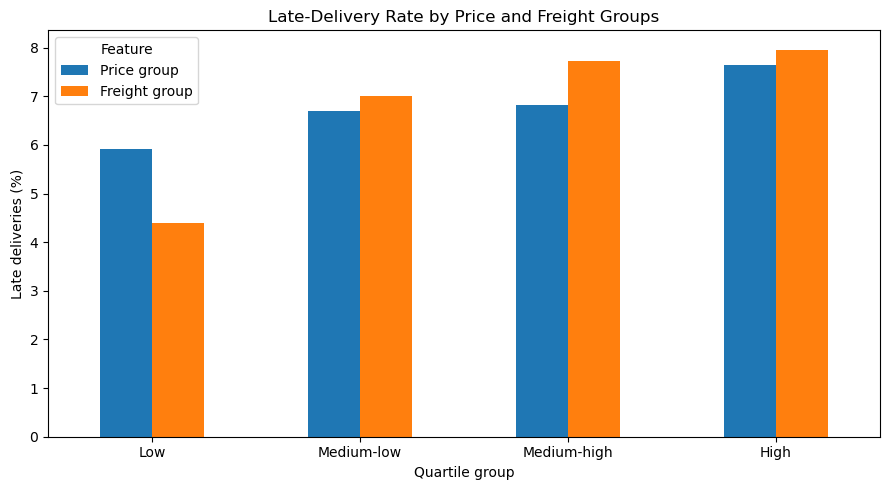

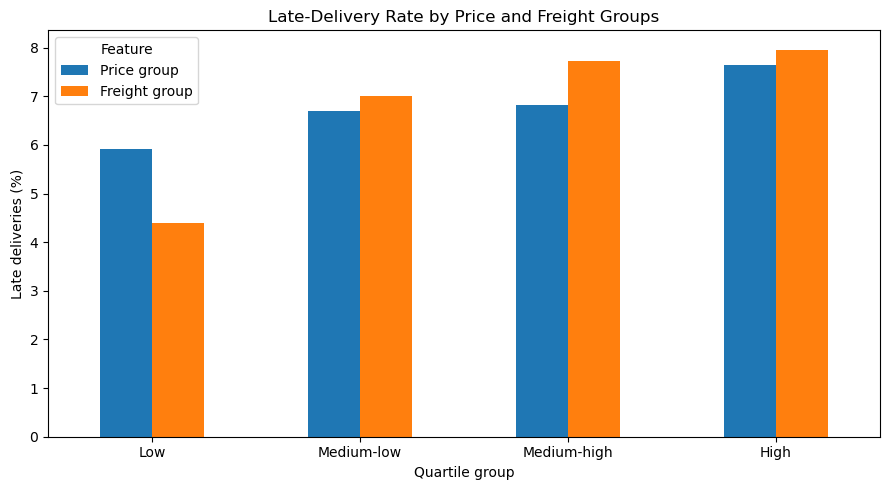

In [34]:
import matplotlib.pyplot as plt

rates = pd.DataFrame({
    "Price group": price_delay_summary["late_rate"],
    "Freight group": freight_delay_summary["late_rate"]
})

ax = rates.plot(kind="bar", figsize=(9, 5))

ax.set_title("Late-Delivery Rate by Price and Freight Groups")
ax.set_xlabel("Quartile group")
ax.set_ylabel("Late deliveries (%)")
ax.legend(title="Feature")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [35]:
model_data["purchase_month"] = (
    model_data["order_purchase_timestamp"].dt.month
)

monthly_summary = model_data.groupby("purchase_month").agg(
    order_count=("late_delivery", "size"),
    late_orders=("late_delivery", "sum"),
    late_rate=("late_delivery", "mean")
)

monthly_summary["late_rate"] = (
    monthly_summary["late_rate"] * 100
).round(2)

display(monthly_summary)

,order_count,late_orders,late_rate
purchase_month,,,
1,7819,425,5.44
2,8208,975,11.88
3,9549,1444,15.12
4,9101,457,5.02
5,10294,549,5.33
6,9231,166,1.80
7,10028,316,3.15
8,10544,515,4.88
9,4151,183,4.41


,order_count,late_orders,late_rate
purchase_month,,,
1,7819,425,5.44
2,8208,975,11.88
3,9549,1444,15.12
4,9101,457,5.02
5,10294,549,5.33
6,9231,166,1.80
7,10028,316,3.15
8,10544,515,4.88
9,4151,183,4.41


In [36]:
model_data["purchase_year"] = (
    model_data["order_purchase_timestamp"].dt.year
)

year_month_summary = model_data.pivot_table(
    index="purchase_year",
    columns="purchase_month",
    values="late_delivery",
    aggfunc="mean"
) * 100

display(year_month_summary.round(2))

purchase_month,1,2,3,4,5,6,7,8,9,10,11,12
purchase_year,,,,,,,,,,,,
2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,0.75,NaN,0.00
2017,2.93,2.96,4.56,6.56,2.99,3.03,2.79,2.91,4.39,4.18,12.4,7.46
2018,5.70,14.13,18.96,4.50,6.56,1.16,3.38,6.19,NaN,NaN,NaN,NaN


purchase_month,1,2,3,4,5,6,7,8,9,10,11,12
purchase_year,,,,,,,,,,,,
2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,0.75,NaN,0.00
2017,2.93,2.96,4.56,6.56,2.99,3.03,2.79,2.91,4.39,4.18,12.4,7.46
2018,5.70,14.13,18.96,4.50,6.56,1.16,3.38,6.19,NaN,NaN,NaN,NaN


In [37]:
year_summary = model_data.groupby("purchase_year").agg(
    order_count=("late_delivery", "size"),
    late_orders=("late_delivery", "sum"),
    late_rate=("late_delivery", "mean")
)

year_summary["late_rate"] = (
    year_summary["late_rate"] * 100
).round(2)

display(year_summary)

,order_count,late_orders,late_rate
purchase_year,,,
2016,267,3,1.12
2017,43426,2453,5.65
2018,52777,4078,7.73


,order_count,late_orders,late_rate
purchase_year,,,
2016,267,3,1.12
2017,43426,2453,5.65
2018,52777,4078,7.73


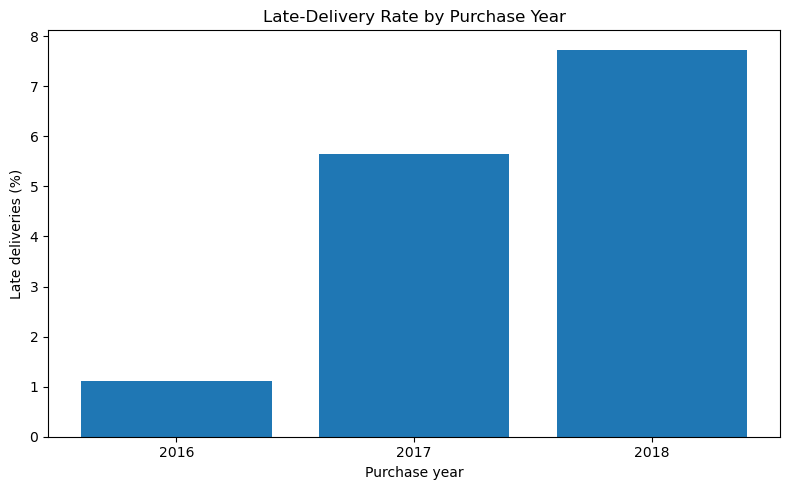

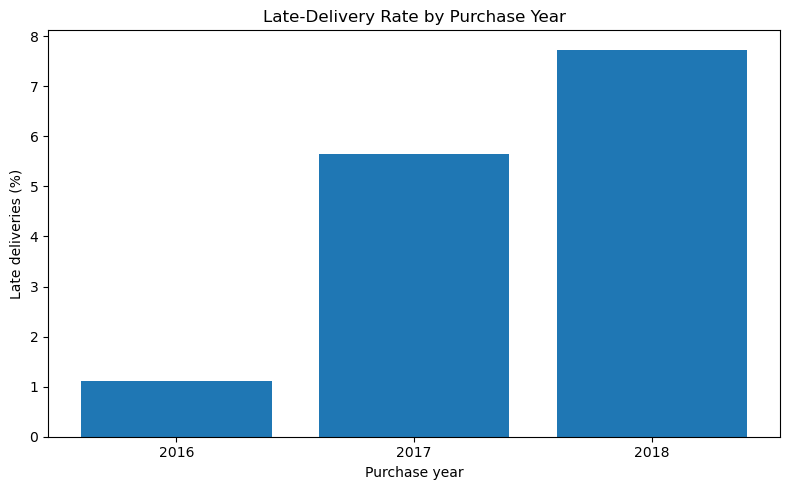

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    year_summary.index.astype(str),
    year_summary["late_rate"]
)

plt.title("Late-Delivery Rate by Purchase Year")
plt.xlabel("Purchase year")
plt.ylabel("Late deliveries (%)")

plt.tight_layout()
plt.show()

In [39]:
feature_availability = pd.DataFrame({
    "column": model_data.columns,
    "missing_values": model_data.isna().sum().values,
    "data_type": model_data.dtypes.astype(str).values
})

display(feature_availability)

,column,missing_values,data_type
0,order_id,0,object
1,customer_id,0,object
2,order_status,0,object
3,order_purchase_timestamp,0,datetime64[ns]
4,order_approved_at,14,datetime64[ns]
5,order_delivered_carrier_date,1,datetime64[ns]
6,order_delivered_customer_date,0,datetime64[ns]
7,order_estimated_delivery_date,0,datetime64[ns]
8,late_delivery,0,int8
9,delivery_delay_days,0,int64


,column,missing_values,data_type
0,order_id,0,object
1,customer_id,0,object
2,order_status,0,object
3,order_purchase_timestamp,0,datetime64[ns]
4,order_approved_at,14,datetime64[ns]
5,order_delivered_carrier_date,1,datetime64[ns]
6,order_delivered_customer_date,0,datetime64[ns]
7,order_estimated_delivery_date,0,datetime64[ns]
8,late_delivery,0,int8
9,delivery_delay_days,0,int64


In [40]:
model_data.loc[
    model_data["order_approved_at"].isna(),
    [
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "late_delivery"
    ]
]

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,late_delivery
5170,e04abd8149ef81b95221e88f6ed9ab6a,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17,0
16097,8a9adc69528e1001fc68dd0aaebbb54a,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21,0
18493,7013bcfc1c97fe719a7b5e05e61c12db,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17,0
21997,5cf925b116421afa85ee25e99b4c34fb,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31,0
22476,12a95a3c06dbaec84bcfb0e2da5d228a,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20,0
26012,c1d4211b3dae76144deccd6c74144a88,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01,0
37156,d69e5d356402adc8cf17e08b5033acfb,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27,0
38169,d77031d6a3c8a52f019764e68f211c69,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22,0
46954,7002a78c79c519ac54022d4f8a65e6e8,2017-01-19 22:26:59,NaT,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16,0
59909,2eecb0d85f281280f79fa00f9cec1a95,2017-02-17 17:21:55,NaT,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20,0


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,late_delivery
5170,e04abd8149ef81b95221e88f6ed9ab6a,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17,0
16097,8a9adc69528e1001fc68dd0aaebbb54a,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21,0
18493,7013bcfc1c97fe719a7b5e05e61c12db,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17,0
21997,5cf925b116421afa85ee25e99b4c34fb,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31,0
22476,12a95a3c06dbaec84bcfb0e2da5d228a,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20,0
26012,c1d4211b3dae76144deccd6c74144a88,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01,0
37156,d69e5d356402adc8cf17e08b5033acfb,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27,0
38169,d77031d6a3c8a52f019764e68f211c69,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22,0
46954,7002a78c79c519ac54022d4f8a65e6e8,2017-01-19 22:26:59,NaT,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16,0
59909,2eecb0d85f281280f79fa00f9cec1a95,2017-02-17 17:21:55,NaT,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20,0


In [41]:
missing_approval = model_data[
    model_data["order_approved_at"].isna()
]

print("Orders missing approval timestamp:", len(missing_approval))

print("\nTarget distribution:")
print(missing_approval["late_delivery"].value_counts())

print(
    "\nMissing approval timestamp percentage:",
    round(
        len(missing_approval) / len(model_data) * 100,
        4
    ),
    "%"
)

Orders missing approval timestamp: 14

Target distribution:
late_delivery
0    14
Name: count, dtype: int64

Missing approval timestamp percentage: 0.0145 %
Orders missing approval timestamp: 14

Target distribution:
late_delivery
0    14
Name: count, dtype: int64

Missing approval timestamp percentage: 0.0145 %


In [42]:
modeling_data = model_data[
    model_data["order_approved_at"].notna()
].copy()

print("Original eligible orders:", len(model_data))
print("Modeling-eligible orders:", len(modeling_data))
print(
    "Orders excluded for missing approval:",
    len(model_data) - len(modeling_data)
)

print("\nTarget distribution:")
print(modeling_data["late_delivery"].value_counts())

Original eligible orders: 96470
Modeling-eligible orders: 96456
Orders excluded for missing approval: 14

Target distribution:
late_delivery
0    89922
1     6534
Name: count, dtype: int64
Original eligible orders: 96470
Modeling-eligible orders: 96456
Orders excluded for missing approval: 14

Target distribution:
late_delivery
0    89922
1     6534
Name: count, dtype: int64


In [43]:
approval_check = (
    modeling_data["order_approved_at"]
    < modeling_data["order_purchase_timestamp"]
)

print(
    "Approval before purchase:",
    approval_check.sum()
)

print(
    "Approval at or after purchase:",
    (~approval_check).sum()
)


Approval before purchase: 0
Approval at or after purchase: 96456
Approval before purchase: 0
Approval at or after purchase: 96456


In [44]:
modeling_data["approval_delay_hours"] = (
    modeling_data["order_approved_at"]
    - modeling_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600

print(
    modeling_data["approval_delay_hours"]
    .describe()
    .round(2)
)

count    96456.00
mean        10.28
std         20.54
min          0.00
25%          0.22
50%          0.34
75%         14.52
max        741.44
Name: approval_delay_hours, dtype: float64
count    96456.00
mean        10.28
std         20.54
min          0.00
25%          0.22
50%          0.34
75%         14.52
max        741.44
Name: approval_delay_hours, dtype: float64


In [45]:
modeling_data.nlargest(
    5, "approval_delay_hours"
)[[
    "order_id",
    "order_purchase_timestamp",
    "order_approved_at",
    "approval_delay_hours",
    "late_delivery"
]]

,order_id,order_purchase_timestamp,order_approved_at,approval_delay_hours,late_delivery
93380,0a93b40850d3f4becf2f276666e01340,2018-01-20 14:24:50,2018-02-20 11:51:27,741.443611,1
54049,f7923db0430587601c2aef15ec4b8af4,2018-01-20 17:38:58,2018-02-20 12:05:54,738.448889,1
86016,de0076b42a023f53b398ce9ab0d9009c,2017-12-04 11:15:54,2017-12-27 14:03:00,554.785000,1
69520,daed0f3aefd193de33c31e21b16a3b3a,2018-03-12 15:21:32,2018-03-29 11:35:16,404.228889,1
71685,9c038e10f14d12a96939a0176c4ecc99,2017-05-26 15:30:49,2017-06-08 23:02:47,319.532778,0


,order_id,order_purchase_timestamp,order_approved_at,approval_delay_hours,late_delivery
93380,0a93b40850d3f4becf2f276666e01340,2018-01-20 14:24:50,2018-02-20 11:51:27,741.443611,1
54049,f7923db0430587601c2aef15ec4b8af4,2018-01-20 17:38:58,2018-02-20 12:05:54,738.448889,1
86016,de0076b42a023f53b398ce9ab0d9009c,2017-12-04 11:15:54,2017-12-27 14:03:00,554.785000,1
69520,daed0f3aefd193de33c31e21b16a3b3a,2018-03-12 15:21:32,2018-03-29 11:35:16,404.228889,1
71685,9c038e10f14d12a96939a0176c4ecc99,2017-05-26 15:30:49,2017-06-08 23:02:47,319.532778,0


In [46]:
modeling_data["approval_delay_group"] = pd.cut(
    modeling_data["approval_delay_hours"],
    bins=[-0.01, 1, 6, 24, float("inf")],
    labels=["0–1 hour", "1–6 hours", "6–24 hours", "Over 24 hours"]
)

approval_summary = modeling_data.groupby(
    "approval_delay_group", observed=False
).agg(
    order_count=("late_delivery", "size"),
    late_orders=("late_delivery", "sum"),
    late_rate=("late_delivery", "mean")
)

approval_summary["late_rate"] = (
    approval_summary["late_rate"] * 100
).round(2)

display(approval_summary)

,order_count,late_orders,late_rate
approval_delay_group,,,
0–1 hour,61705,3884,6.29
1–6 hours,5868,485,8.27
6–24 hours,12010,795,6.62
Over 24 hours,16873,1370,8.12


,order_count,late_orders,late_rate
approval_delay_group,,,
0–1 hour,61705,3884,6.29
1–6 hours,5868,485,8.27
6–24 hours,12010,795,6.62
Over 24 hours,16873,1370,8.12


In [47]:
modeling_data["approval_to_carrier_hours"] = (
    modeling_data["order_delivered_carrier_date"]
    - modeling_data["order_approved_at"]
).dt.total_seconds() / 3600

print(
    modeling_data["approval_to_carrier_hours"]
    .describe()
    .round(2)
)

count    96455.00
mean        67.18
std         84.89
min      -4109.26
25%         20.98
50%         43.58
75%         85.80
max       3018.30
Name: approval_to_carrier_hours, dtype: float64
count    96455.00
mean        67.18
std         84.89
min      -4109.26
25%         20.98
50%         43.58
75%         85.80
max       3018.30
Name: approval_to_carrier_hours, dtype: float64


In [48]:
carrier_before_approval = (
    modeling_data["order_delivered_carrier_date"]
    < modeling_data["order_approved_at"]
)

print(
    "Carrier timestamp before approval:",
    carrier_before_approval.sum()
)

print(
    "Missing carrier timestamps:",
    modeling_data["order_delivered_carrier_date"].isna().sum()
)

Carrier timestamp before approval: 1350
Missing carrier timestamps: 1
Carrier timestamp before approval: 1350
Missing carrier timestamps: 1


In [49]:
modeling_data.loc[
    modeling_data["order_delivered_carrier_date"]
    < modeling_data["order_approved_at"],
    [
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "late_delivery"
    ]
].head()

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,late_delivery
14,dcb36b511fcac050b97cd5c05de84dc3,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00,2018-06-21 15:34:32,0
62,688052146432ef8253587b930b01a06d,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58,0
193,58d4c4747ee059eeeb865b349b41f53a,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00,2018-07-25 23:58:19,0
204,412fccb2b44a99b36714bca3fef8ad7b,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00,2018-07-24 19:26:42,0
401,56a4ac10a4a8f2ba7693523bb439eede,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00,2018-07-28 00:05:39,0


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,late_delivery
14,dcb36b511fcac050b97cd5c05de84dc3,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00,2018-06-21 15:34:32,0
62,688052146432ef8253587b930b01a06d,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58,0
193,58d4c4747ee059eeeb865b349b41f53a,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00,2018-07-25 23:58:19,0
204,412fccb2b44a99b36714bca3fef8ad7b,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00,2018-07-24 19:26:42,0
401,56a4ac10a4a8f2ba7693523bb439eede,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00,2018-07-28 00:05:39,0


In [50]:
bad_sequence = modeling_data[
    modeling_data["order_delivered_carrier_date"]
    < modeling_data["order_approved_at"]
]

display(
    bad_sequence[[
        "order_id",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]].head(5).reset_index(drop=True)
)

,order_id,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
0,dcb36b511fcac050b97cd5c05de84dc3,2018-06-12 23:31:02,2018-06-11 14:54:00,2018-06-21 15:34:32
1,688052146432ef8253587b930b01a06d,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58
2,58d4c4747ee059eeeb865b349b41f53a,2018-07-26 23:31:53,2018-07-24 12:57:00,2018-07-25 23:58:19
3,412fccb2b44a99b36714bca3fef8ad7b,2018-07-23 12:31:53,2018-07-23 12:24:00,2018-07-24 19:26:42
4,56a4ac10a4a8f2ba7693523bb439eede,2018-07-27 23:31:09,2018-07-24 14:03:00,2018-07-28 00:05:39


,order_id,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
0,dcb36b511fcac050b97cd5c05de84dc3,2018-06-12 23:31:02,2018-06-11 14:54:00,2018-06-21 15:34:32
1,688052146432ef8253587b930b01a06d,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58
2,58d4c4747ee059eeeb865b349b41f53a,2018-07-26 23:31:53,2018-07-24 12:57:00,2018-07-25 23:58:19
3,412fccb2b44a99b36714bca3fef8ad7b,2018-07-23 12:31:53,2018-07-23 12:24:00,2018-07-24 19:26:42
4,56a4ac10a4a8f2ba7693523bb439eede,2018-07-27 23:31:09,2018-07-24 14:03:00,2018-07-28 00:05:39


In [51]:
delivery_before_carrier = (
    modeling_data["order_delivered_customer_date"]
    < modeling_data["order_delivered_carrier_date"]
)

print(
    "Customer delivery before carrier handover:",
    delivery_before_carrier.sum()
)


Customer delivery before carrier handover: 23
Customer delivery before carrier handover: 23


In [52]:
delivery_before_carrier = (
    modeling_data["order_delivered_customer_date"]
    < modeling_data["order_delivered_carrier_date"]
)

display(
    modeling_data.loc[
        delivery_before_carrier,
        [
            "order_id",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "late_delivery"
        ]
    ].head(5).reset_index(drop=True)
)

,order_id,order_delivered_carrier_date,order_delivered_customer_date,late_delivery
0,a1abeb653a4d4cd1e142ccb8c82cd069,2017-07-28 16:57:58,2017-07-25 19:32:56,0
1,383aa8b2724fe452d9ccd9934a8c628b,2017-07-07 17:22:41,2017-07-06 14:27:51,0
2,cb1134f9010d242e9515ad1c78ec0c39,2017-07-20 19:22:02,2017-07-19 14:13:28,0
3,dceb62e8fa94b46006c9554fed743df0,2017-08-01 18:23:30,2017-07-26 18:09:10,0
4,5f9d46795c3126674e52becb3a1a517f,2017-07-20 23:03:42,2017-07-20 18:52:41,0


,order_id,order_delivered_carrier_date,order_delivered_customer_date,late_delivery
0,a1abeb653a4d4cd1e142ccb8c82cd069,2017-07-28 16:57:58,2017-07-25 19:32:56,0
1,383aa8b2724fe452d9ccd9934a8c628b,2017-07-07 17:22:41,2017-07-06 14:27:51,0
2,cb1134f9010d242e9515ad1c78ec0c39,2017-07-20 19:22:02,2017-07-19 14:13:28,0
3,dceb62e8fa94b46006c9554fed743df0,2017-08-01 18:23:30,2017-07-26 18:09:10,0
4,5f9d46795c3126674e52becb3a1a517f,2017-07-20 23:03:42,2017-07-20 18:52:41,0


In [53]:
print(
    "Carrier before approval:",
    (
        modeling_data["order_delivered_carrier_date"]
        < modeling_data["order_approved_at"]
    ).sum()
)

print(
    "Customer delivery before carrier:",
    (
        modeling_data["order_delivered_customer_date"]
        < modeling_data["order_delivered_carrier_date"]
    ).sum()
)

print(
    "Missing carrier timestamp:",
    modeling_data["order_delivered_carrier_date"].isna().sum()
)

Carrier before approval: 1350
Customer delivery before carrier: 23
Missing carrier timestamp: 1
Carrier before approval: 1350
Customer delivery before carrier: 23
Missing carrier timestamp: 1


In [54]:
candidate_features = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_estimated_delivery_date",
    "promised_delivery_days",
    "approval_delay_hours",
    "total_items",
    "total_price",
    "total_freight",
    "seller_count"
]

print("Candidate features:")
for feature in candidate_features:
    print("-", feature)

print("\nTarget: late_delivery")

Candidate features:
- order_purchase_timestamp
- order_approved_at
- order_estimated_delivery_date
- promised_delivery_days
- approval_delay_hours
- total_items
- total_price
- total_freight
- seller_count

Target: late_delivery
Candidate features:
- order_purchase_timestamp
- order_approved_at
- order_estimated_delivery_date
- promised_delivery_days
- approval_delay_hours
- total_items
- total_price
- total_freight
- seller_count

Target: late_delivery


In [55]:
modeling_data["purchase_month"] = (
    modeling_data["order_purchase_timestamp"].dt.month
)

modeling_data["purchase_day_of_week"] = (
    modeling_data["order_purchase_timestamp"].dt.dayofweek
)

print(
    modeling_data[
        [
            "order_purchase_timestamp",
            "purchase_month",
            "purchase_day_of_week"
        ]
    ].head()
)

  order_purchase_timestamp  purchase_month  purchase_day_of_week
0      2017-10-02 10:56:33              10                     0
1      2018-07-24 20:41:37               7                     1
2      2018-08-08 08:38:49               8                     2
3      2017-11-18 19:28:06              11                     5
4      2018-02-13 21:18:39               2                     1
  order_purchase_timestamp  purchase_month  purchase_day_of_week
0      2017-10-02 10:56:33              10                     0
1      2018-07-24 20:41:37               7                     1
2      2018-08-08 08:38:49               8                     2
3      2017-11-18 19:28:06              11                     5
4      2018-02-13 21:18:39               2                     1


In [56]:
modeling_data["purchase_hour"] = (
    modeling_data["order_purchase_timestamp"].dt.hour
)

print(
    modeling_data[
        [
            "order_purchase_timestamp",
            "purchase_hour"
        ]
    ].head()
)

  order_purchase_timestamp  purchase_hour
0      2017-10-02 10:56:33             10
1      2018-07-24 20:41:37             20
2      2018-08-08 08:38:49              8
3      2017-11-18 19:28:06             19
4      2018-02-13 21:18:39             21
  order_purchase_timestamp  purchase_hour
0      2017-10-02 10:56:33             10
1      2018-07-24 20:41:37             20
2      2018-08-08 08:38:49              8
3      2017-11-18 19:28:06             19
4      2018-02-13 21:18:39             21


In [57]:
modeling_data["approval_day_of_week"] = (
    modeling_data["order_approved_at"].dt.dayofweek
)

print(
    modeling_data[
        [
            "order_approved_at",
            "approval_day_of_week"
        ]
    ].head()
)

    order_approved_at  approval_day_of_week
0 2017-10-02 11:07:15                     0
1 2018-07-26 03:24:27                     3
2 2018-08-08 08:55:23                     2
3 2017-11-18 19:45:59                     5
4 2018-02-13 22:20:29                     1
    order_approved_at  approval_day_of_week
0 2017-10-02 11:07:15                     0
1 2018-07-26 03:24:27                     3
2 2018-08-08 08:55:23                     2
3 2017-11-18 19:45:59                     5
4 2018-02-13 22:20:29                     1


In [58]:
modeling_data["approval_hour"] = (
    modeling_data["order_approved_at"].dt.hour
)

print(
    modeling_data[
        ["order_approved_at", "approval_hour"]
    ].head()
)

    order_approved_at  approval_hour
0 2017-10-02 11:07:15             11
1 2018-07-26 03:24:27              3
2 2018-08-08 08:55:23              8
3 2017-11-18 19:45:59             19
4 2018-02-13 22:20:29             22
    order_approved_at  approval_hour
0 2017-10-02 11:07:15             11
1 2018-07-26 03:24:27              3
2 2018-08-08 08:55:23              8
3 2017-11-18 19:45:59             19
4 2018-02-13 22:20:29             22


In [59]:
modeling_data["approval_hour"].value_counts().sort_index()

approval_hour
0     1924
1     1481
2     6855
3     5378
4     3254
5     1019
6      902
7     1445
8     2204
9     3700
10    4713
11    5184
12    4454
13    5409
14    5192
15    5148
16    5731
17    5324
18    4909
19    4870
20    4806
21    4574
22    4556
23    3424
Name: count, dtype: int64

approval_hour
0     1924
1     1481
2     6855
3     5378
4     3254
5     1019
6      902
7     1445
8     2204
9     3700
10    4713
11    5184
12    4454
13    5409
14    5192
15    5148
16    5731
17    5324
18    4909
19    4870
20    4806
21    4574
22    4556
23    3424
Name: count, dtype: int64

In [60]:
approval_hour_analysis = (
    modeling_data.groupby("approval_hour")
    .agg(
        total_orders=("late_delivery", "size"),
        late_orders=("late_delivery", "sum"),
        late_rate=("late_delivery", "mean")
    )
    .reset_index()
)

approval_hour_analysis["late_rate_pct"] = (
    approval_hour_analysis["late_rate"] * 100
)

approval_hour_analysis[
    ["approval_hour", "total_orders", "late_orders", "late_rate_pct"]
]

,approval_hour,total_orders,late_orders,late_rate_pct
0,0,1924,150,7.796258
1,1,1481,96,6.482107
2,2,6855,525,7.658643
3,3,5378,422,7.846783
4,4,3254,207,6.361401
5,5,1019,55,5.397448
6,6,902,59,6.541020
7,7,1445,101,6.989619
8,8,2204,119,5.399274
9,9,3700,252,6.810811


,approval_hour,total_orders,late_orders,late_rate_pct
0,0,1924,150,7.796258
1,1,1481,96,6.482107
2,2,6855,525,7.658643
3,3,5378,422,7.846783
4,4,3254,207,6.361401
5,5,1019,55,5.397448
6,6,902,59,6.541020
7,7,1445,101,6.989619
8,8,2204,119,5.399274
9,9,3700,252,6.810811


In [61]:
approval_hour_analysis[
    ["approval_hour", "total_orders", "late_orders", "late_rate_pct"]
].round(2).to_string(index=False)

' approval_hour  total_orders  late_orders  late_rate_pct\n             0          1924          150           7.80\n             1          1481           96           6.48\n             2          6855          525           7.66\n             3          5378          422           7.85\n             4          3254          207           6.36\n             5          1019           55           5.40\n             6           902           59           6.54\n             7          1445          101           6.99\n             8          2204          119           5.40\n             9          3700          252           6.81\n            10          4713          269           5.71\n            11          5184          347           6.69\n            12          4454          304           6.83\n            13          5409          366           6.77\n            14          5192          357           6.88\n            15          5148          382           7.42\n            1

' approval_hour  total_orders  late_orders  late_rate_pct\n             0          1924          150           7.80\n             1          1481           96           6.48\n             2          6855          525           7.66\n             3          5378          422           7.85\n             4          3254          207           6.36\n             5          1019           55           5.40\n             6           902           59           6.54\n             7          1445          101           6.99\n             8          2204          119           5.40\n             9          3700          252           6.81\n            10          4713          269           5.71\n            11          5184          347           6.69\n            12          4454          304           6.83\n            13          5409          366           6.77\n            14          5192          357           6.88\n            15          5148          382           7.42\n            1

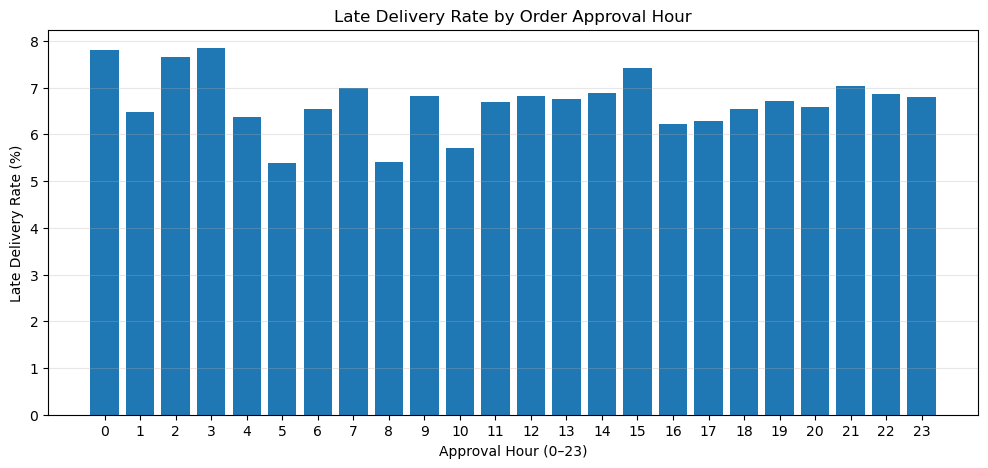

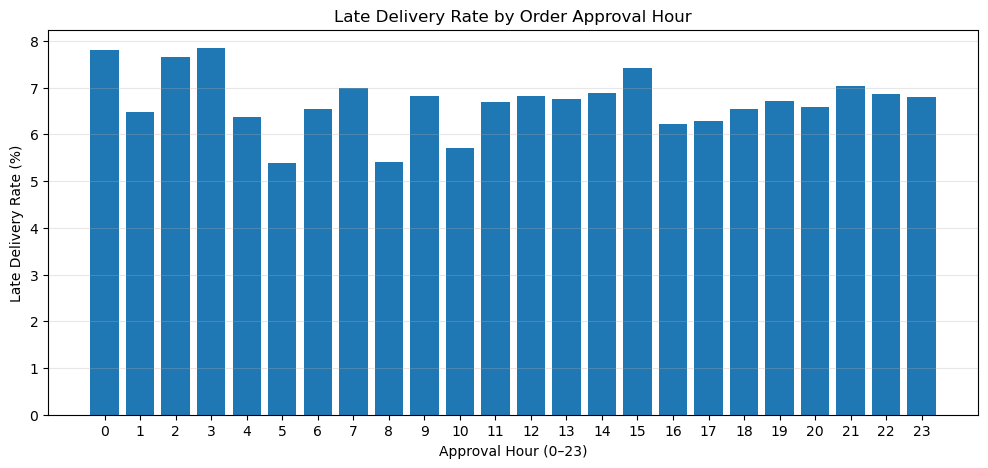

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    approval_hour_analysis["approval_hour"],
    approval_hour_analysis["late_rate_pct"]
)

plt.xlabel("Approval Hour (0–23)")
plt.ylabel("Late Delivery Rate (%)")
plt.title("Late Delivery Rate by Order Approval Hour")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [63]:
approval_day_analysis = (
    modeling_data.groupby("approval_day_of_week")
    .agg(
        total_orders=("late_delivery", "size"),
        late_orders=("late_delivery", "sum"),
        late_rate=("late_delivery", "mean")
    )
    .reset_index()
)

approval_day_analysis["late_rate_pct"] = (
    approval_day_analysis["late_rate"] * 100
)

approval_day_analysis[
    ["approval_day_of_week", "total_orders", "late_orders", "late_rate_pct"]
].round(2)

,approval_day_of_week,total_orders,late_orders,late_rate_pct
0,0,12613,909,7.21
1,1,18643,1270,6.81
2,2,15330,1038,6.77
3,3,15045,934,6.21
4,4,14218,1054,7.41
5,5,11836,783,6.62
6,6,8771,546,6.23


,approval_day_of_week,total_orders,late_orders,late_rate_pct
0,0,12613,909,7.21
1,1,18643,1270,6.81
2,2,15330,1038,6.77
3,3,15045,934,6.21
4,4,14218,1054,7.41
5,5,11836,783,6.62
6,6,8771,546,6.23


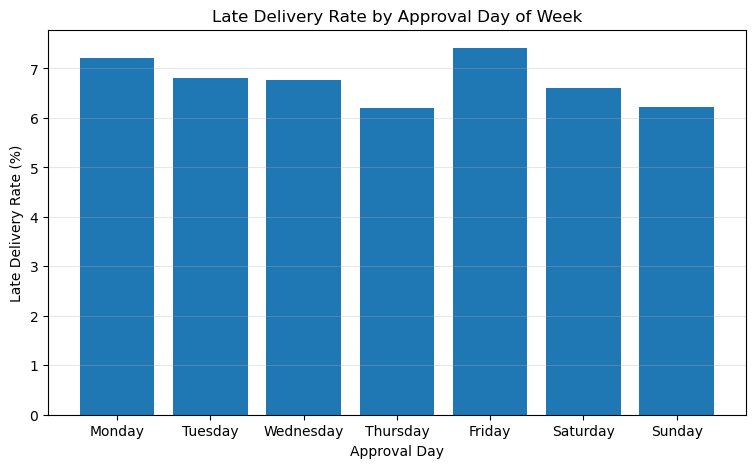

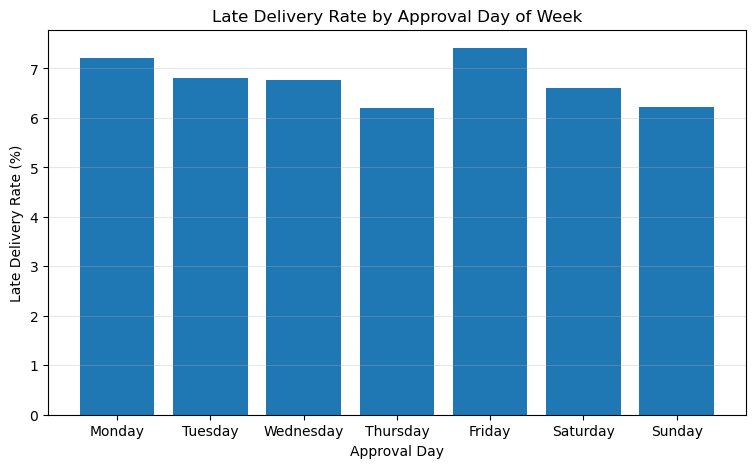

In [64]:
import matplotlib.pyplot as plt

day_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(9, 5))

plt.bar(
    day_names,
    approval_day_analysis["late_rate_pct"]
)

plt.xlabel("Approval Day")
plt.ylabel("Late Delivery Rate (%)")
plt.title("Late Delivery Rate by Approval Day of Week")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [65]:
purchase_day_analysis = (
    modeling_data.groupby("purchase_day_of_week")
    .agg(
        total_orders=("late_delivery", "size"),
        late_orders=("late_delivery", "sum"),
        late_rate=("late_delivery", "mean")
    )
    .reset_index()
)

purchase_day_analysis["late_rate_pct"] = (
    purchase_day_analysis["late_rate"] * 100
)

purchase_day_analysis[
    [
        "purchase_day_of_week",
        "total_orders",
        "late_orders",
        "late_rate_pct"
    ]
].round(2)

,purchase_day_of_week,total_orders,late_orders,late_rate_pct
0,0,15701,1168,7.44
1,1,15502,1093,7.05
2,2,15074,990,6.57
3,3,14320,903,6.31
4,4,13681,960,7.02
5,5,10547,696,6.60
6,6,11631,724,6.22


,purchase_day_of_week,total_orders,late_orders,late_rate_pct
0,0,15701,1168,7.44
1,1,15502,1093,7.05
2,2,15074,990,6.57
3,3,14320,903,6.31
4,4,13681,960,7.02
5,5,10547,696,6.60
6,6,11631,724,6.22


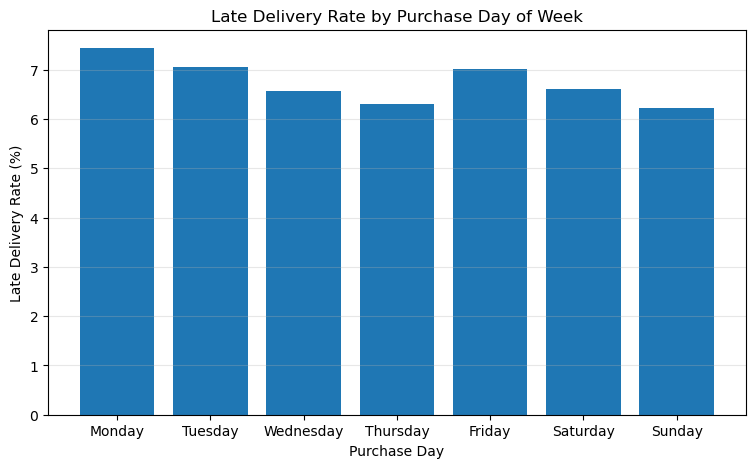

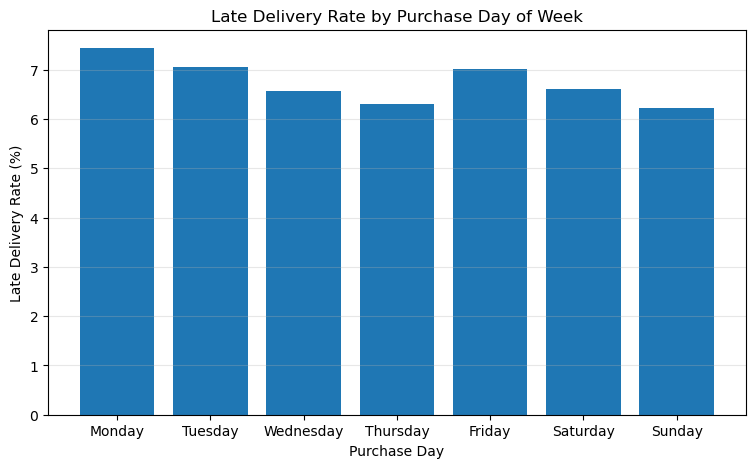

In [66]:
import matplotlib.pyplot as plt

day_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(9, 5))

plt.bar(
    day_names,
    purchase_day_analysis["late_rate_pct"]
)

plt.xlabel("Purchase Day")
plt.ylabel("Late Delivery Rate (%)")
plt.title("Late Delivery Rate by Purchase Day of Week")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [67]:
time_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "approval_day_of_week",
    "approval_hour",
    "approval_delay_hours"
]

modeling_data[time_features].isna().sum()

purchase_month          0
purchase_day_of_week    0
purchase_hour           0
approval_day_of_week    0
approval_hour           0
approval_delay_hours    0
dtype: int64

purchase_month          0
purchase_day_of_week    0
purchase_hour           0
approval_day_of_week    0
approval_hour           0
approval_delay_hours    0
dtype: int64

In [68]:
print("Dataset shape:", modeling_data.shape)

print("\nDuplicate order IDs:",
      modeling_data["order_id"].duplicated().sum())

print("\nTarget distribution:")
print(modeling_data["late_delivery"].value_counts())

print("\nTarget percentages:")
print(
    (modeling_data["late_delivery"].value_counts(normalize=True) * 100)
    .round(2)
)

Dataset shape: (96456, 28)

Duplicate order IDs: 0

Target distribution:
late_delivery
0    89922
1     6534
Name: count, dtype: int64

Target percentages:
late_delivery
0    93.23
1     6.77
Name: proportion, dtype: float64
Dataset shape: (96456, 28)

Duplicate order IDs: 0

Target distribution:
late_delivery
0    89922
1     6534
Name: count, dtype: int64

Target percentages:
late_delivery
0    93.23
1     6.77
Name: proportion, dtype: float64


In [69]:
for column in modeling_data.columns:
    print(column)

order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date
late_delivery
delivery_delay_days
promised_delivery_days
total_items
total_price
total_freight
seller_count
_merge
item_group
price_group
freight_group
purchase_month
purchase_year
approval_delay_hours
approval_delay_group
approval_to_carrier_hours
purchase_day_of_week
purchase_hour
approval_day_of_week
approval_hour
order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date
late_delivery
delivery_delay_days
promised_delivery_days
total_items
total_price
total_freight
seller_count
_merge
item_group
price_group
freight_group
purchase_month
purchase_year
approval_delay_hours
approval_delay_group
approval_to_carrier_hours
purchase_day_of_week
purchase_hour
approval_day_of_week
approval_hour


In [70]:
candidate_numeric_features = [
    "promised_delivery_days",
    "total_items",
    "total_price",
    "total_freight",
    "seller_count",
    "purchase_month",
    "purchase_year",
    "purchase_day_of_week",
    "purchase_hour",
    "approval_day_of_week",
    "approval_hour",
    "approval_delay_hours"
]

modeling_data[candidate_numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
promised_delivery_days,96456.0,24.371112,8.757573,3.00,19.000000,24.000000,29.000000,156.000000
total_items,96456.0,1.142220,0.538854,1.00,1.000000,1.000000,1.000000,21.000000
total_price,96456.0,137.042574,209.064238,0.85,45.900000,86.500000,149.900000,13440.000000
total_freight,96456.0,22.786159,21.561315,0.00,13.850000,17.170000,24.020000,1794.960000
seller_count,96456.0,1.013903,0.123550,1.00,1.000000,1.000000,1.000000,5.000000
purchase_month,96456.0,6.031652,3.228319,1.00,3.000000,6.000000,8.000000,12.000000
purchase_year,96456.0,2017.544393,0.503555,2016.00,2017.000000,2018.000000,2018.000000,2018.000000
purchase_day_of_week,96456.0,2.756231,1.967038,0.00,1.000000,3.000000,4.000000,6.000000
purchase_hour,96456.0,14.773099,5.328400,0.00,11.000000,15.000000,19.000000,23.000000
approval_day_of_week,96456.0,2.727834,1.868562,0.00,1.000000,3.000000,4.000000,6.000000


,count,mean,std,min,25%,50%,75%,max
promised_delivery_days,96456.0,24.371112,8.757573,3.00,19.000000,24.000000,29.000000,156.000000
total_items,96456.0,1.142220,0.538854,1.00,1.000000,1.000000,1.000000,21.000000
total_price,96456.0,137.042574,209.064238,0.85,45.900000,86.500000,149.900000,13440.000000
total_freight,96456.0,22.786159,21.561315,0.00,13.850000,17.170000,24.020000,1794.960000
seller_count,96456.0,1.013903,0.123550,1.00,1.000000,1.000000,1.000000,5.000000
purchase_month,96456.0,6.031652,3.228319,1.00,3.000000,6.000000,8.000000,12.000000
purchase_year,96456.0,2017.544393,0.503555,2016.00,2017.000000,2018.000000,2018.000000,2018.000000
purchase_day_of_week,96456.0,2.756231,1.967038,0.00,1.000000,3.000000,4.000000,6.000000
purchase_hour,96456.0,14.773099,5.328400,0.00,11.000000,15.000000,19.000000,23.000000
approval_day_of_week,96456.0,2.727834,1.868562,0.00,1.000000,3.000000,4.000000,6.000000


In [71]:
modeling_data.nlargest(10, "approval_delay_hours")[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "approval_delay_hours",
        "late_delivery"
    ]
]


,order_id,order_purchase_timestamp,order_approved_at,approval_delay_hours,late_delivery
93380,0a93b40850d3f4becf2f276666e01340,2018-01-20 14:24:50,2018-02-20 11:51:27,741.443611,1
54049,f7923db0430587601c2aef15ec4b8af4,2018-01-20 17:38:58,2018-02-20 12:05:54,738.448889,1
86016,de0076b42a023f53b398ce9ab0d9009c,2017-12-04 11:15:54,2017-12-27 14:03:00,554.785000,1
69520,daed0f3aefd193de33c31e21b16a3b3a,2018-03-12 15:21:32,2018-03-29 11:35:16,404.228889,1
71685,9c038e10f14d12a96939a0176c4ecc99,2017-05-26 15:30:49,2017-06-08 23:02:47,319.532778,0
35577,14ef2221cc3570aa6ce512fc353529b3,2018-02-09 09:27:56,2018-02-22 11:15:51,313.798611,0
13770,0c1426109d8295a688ee4182016bba59,2017-11-24 21:24:29,2017-12-07 09:50:08,300.427500,0
73622,483b53ea654d3566427a092cdef047fd,2017-08-03 15:59:11,2017-08-16 03:30:15,299.517778,0
33454,f5194ba2a4560ffa0e87746852c61fc1,2017-11-24 22:53:26,2017-12-07 09:50:07,298.944722,0
66372,70f357cca87c1162357bf3c0a993cbe5,2017-09-01 18:40:11,2017-09-13 22:04:49,291.410556,0


,order_id,order_purchase_timestamp,order_approved_at,approval_delay_hours,late_delivery
93380,0a93b40850d3f4becf2f276666e01340,2018-01-20 14:24:50,2018-02-20 11:51:27,741.443611,1
54049,f7923db0430587601c2aef15ec4b8af4,2018-01-20 17:38:58,2018-02-20 12:05:54,738.448889,1
86016,de0076b42a023f53b398ce9ab0d9009c,2017-12-04 11:15:54,2017-12-27 14:03:00,554.785000,1
69520,daed0f3aefd193de33c31e21b16a3b3a,2018-03-12 15:21:32,2018-03-29 11:35:16,404.228889,1
71685,9c038e10f14d12a96939a0176c4ecc99,2017-05-26 15:30:49,2017-06-08 23:02:47,319.532778,0
35577,14ef2221cc3570aa6ce512fc353529b3,2018-02-09 09:27:56,2018-02-22 11:15:51,313.798611,0
13770,0c1426109d8295a688ee4182016bba59,2017-11-24 21:24:29,2017-12-07 09:50:08,300.427500,0
73622,483b53ea654d3566427a092cdef047fd,2017-08-03 15:59:11,2017-08-16 03:30:15,299.517778,0
33454,f5194ba2a4560ffa0e87746852c61fc1,2017-11-24 22:53:26,2017-12-07 09:50:07,298.944722,0
66372,70f357cca87c1162357bf3c0a993cbe5,2017-09-01 18:40:11,2017-09-13 22:04:49,291.410556,0


In [72]:
delay_thresholds = [24, 48, 168]

for hours in delay_thresholds:
    count = (
        modeling_data["approval_delay_hours"] > hours
    ).sum()

    percentage = count / len(modeling_data) * 100

    print(
        f"More than {hours:>3} hours: "
        f"{count:>6} orders ({percentage:.2f}%)"
    )

More than  24 hours:  16873 orders (17.49%)
More than  48 hours:   4981 orders (5.16%)
More than 168 hours:     68 orders (0.07%)
More than  24 hours:  16873 orders (17.49%)
More than  48 hours:   4981 orders (5.16%)
More than 168 hours:     68 orders (0.07%)


# MACHINE LEARNING

In [73]:
candidate_features = [
    "total_items",
    "total_price",
    "total_freight",
    "seller_count",
    "promised_delivery_days",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "approval_day_of_week",
    "approval_hour",
    "approval_delay_hours"
]

target = "late_delivery"

print("Number of candidate features:", len(candidate_features))
print("\nCandidate features:")
print(candidate_features)
print("\nTarget:", target)

Number of candidate features: 11

Candidate features:
['total_items', 'total_price', 'total_freight', 'seller_count', 'promised_delivery_days', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'approval_day_of_week', 'approval_hour', 'approval_delay_hours']

Target: late_delivery
Number of candidate features: 11

Candidate features:
['total_items', 'total_price', 'total_freight', 'seller_count', 'promised_delivery_days', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'approval_day_of_week', 'approval_hour', 'approval_delay_hours']

Target: late_delivery


In [74]:
X = modeling_data[candidate_features].copy()
y = modeling_data[target].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nMissing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

print("\nFirst 5 rows of X:")
display(X.head())

Feature matrix shape: (96456, 11)
Target vector shape: (96456,)

Missing values in X: 0
Missing values in y: 0

First 5 rows of X:


,total_items,total_price,total_freight,seller_count,promised_delivery_days,purchase_month,purchase_day_of_week,purchase_hour,approval_day_of_week,approval_hour,approval_delay_hours
0,1,29.99,8.72,1,16,10,0,10,0,11,0.178333
1,1,118.70,22.76,1,20,7,1,20,3,3,30.713889
2,1,159.90,19.22,1,27,8,2,8,2,8,0.276111
3,1,45.00,27.20,1,27,11,5,19,5,19,0.298056
4,1,19.90,8.72,1,13,2,1,21,1,22,1.030556


Feature matrix shape: (96456, 11)
Target vector shape: (96456,)

Missing values in X: 0
Missing values in y: 0

First 5 rows of X:


,total_items,total_price,total_freight,seller_count,promised_delivery_days,purchase_month,purchase_day_of_week,purchase_hour,approval_day_of_week,approval_hour,approval_delay_hours
0,1,29.99,8.72,1,16,10,0,10,0,11,0.178333
1,1,118.70,22.76,1,20,7,1,20,3,3,30.713889
2,1,159.90,19.22,1,27,8,2,8,2,8,0.276111
3,1,45.00,27.20,1,27,11,5,19,5,19,0.298056
4,1,19.90,8.72,1,13,2,1,21,1,22,1.030556


In [75]:
# Instead of randomly splitting orders, we'll train on older orders and test on newer ones. This better simulates how our model would perform on future orders.

print("Earliest purchase:", modeling_data["order_purchase_timestamp"].min())
print("Latest purchase:", modeling_data["order_purchase_timestamp"].max())

Earliest purchase: 2016-09-15 12:16:38
Latest purchase: 2018-08-29 15:00:37
Earliest purchase: 2016-09-15 12:16:38
Latest purchase: 2018-08-29 15:00:37


In [76]:
cutoff_date = pd.Timestamp("2018-04-01")

train_mask = (
    modeling_data["order_purchase_timestamp"] < cutoff_date
)

test_mask = ~train_mask

print("Training orders:", train_mask.sum())
print("Test orders:", test_mask.sum())

print("\nTraining late-delivery rate (%):")
print(
    modeling_data.loc[train_mask, "late_delivery"].mean() * 100
)

print("\nTest late-delivery rate (%):")
print(
    modeling_data.loc[test_mask, "late_delivery"].mean() * 100
)

Training orders: 64306
Test orders: 32150

Training late-delivery rate (%):
7.951046558641495

Test late-delivery rate (%):
4.419906687402799
Training orders: 64306
Test orders: 32150

Training late-delivery rate (%):
7.951046558641495

Test late-delivery rate (%):
4.419906687402799


In [77]:
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (64306, 11)
X_test:  (32150, 11)
y_train: (64306,)
y_test:  (32150,)
X_train: (64306, 11)
X_test:  (32150, 11)
y_train: (64306,)
y_test:  (32150,)


In [78]:
for i, feature in enumerate(candidate_features, start=1):
    print(f"{i}. {feature}")

1. total_items
2. total_price
3. total_freight
4. seller_count
5. promised_delivery_days
6. purchase_month
7. purchase_day_of_week
8. purchase_hour
9. approval_day_of_week
10. approval_hour
11. approval_delay_hours
1. total_items
2. total_price
3. total_freight
4. seller_count
5. promised_delivery_days
6. purchase_month
7. purchase_day_of_week
8. purchase_hour
9. approval_day_of_week
10. approval_hour
11. approval_delay_hours


In [79]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled training shape: (64306, 11)
Scaled test shape: (32150, 11)
Scaled training shape: (64306, 11)
Scaled test shape: (32150, 11)


In [80]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!
Logistic Regression training completed!


In [81]:
y_pred = logistic_model.predict(X_test_scaled)

print("Predictions generated successfully!")
print("Total predictions:", len(y_pred))

print("\nPredicted classes:")
print(pd.Series(y_pred).value_counts().sort_index())

Predictions generated successfully!
Total predictions: 32150

Predicted classes:
0    13270
1    18880
Name: count, dtype: int64
Predictions generated successfully!
Total predictions: 32150

Predicted classes:
0    13270
1    18880
Name: count, dtype: int64


              precision    recall  f1-score   support

 On-time (0)       0.98      0.42      0.59     30729
    Late (1)       0.06      0.80      0.11      1421

    accuracy                           0.44     32150
   macro avg       0.52      0.61      0.35     32150
weighted avg       0.94      0.44      0.57     32150



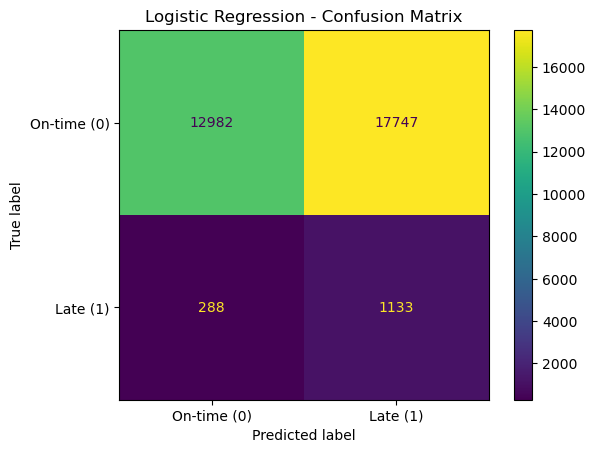

              precision    recall  f1-score   support

 On-time (0)       0.98      0.42      0.59     30729
    Late (1)       0.06      0.80      0.11      1421

    accuracy                           0.44     32150
   macro avg       0.52      0.61      0.35     32150
weighted avg       0.94      0.44      0.57     32150



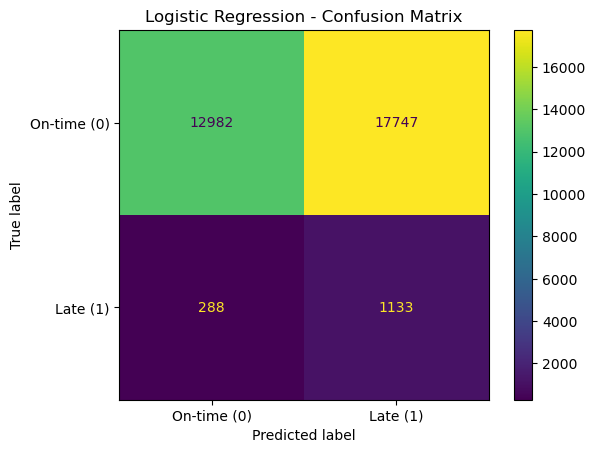

In [82]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print(classification_report(
    y_test,
    y_pred,
    target_names=["On-time (0)", "Late (1)"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["On-time (0)", "Late (1)"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [83]:
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predicted probability summary:")
print(pd.Series(y_prob).describe().round(4))

print("\nProbability percentiles:")
print(
    pd.Series(y_prob)
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(4)
)

Predicted probability summary:
count    32150.0000
mean         0.5113
std          0.0919
min          0.0004
25%          0.4722
50%          0.5124
75%          0.5470
max          1.0000
dtype: float64

Probability percentiles:
0.50    0.5124
0.75    0.5470
0.90    0.5975
0.95    0.6533
0.99    0.7980
dtype: float64
Predicted probability summary:
count    32150.0000
mean         0.5113
std          0.0919
min          0.0004
25%          0.4722
50%          0.5124
75%          0.5470
max          1.0000
dtype: float64

Probability percentiles:
0.50    0.5124
0.75    0.5470
0.90    0.5975
0.95    0.6533
0.99    0.7980
dtype: float64


In [84]:
from sklearn.metrics import classification_report

threshold = 0.70

y_pred_70 = (y_prob >= threshold).astype(int)

print("Predicted late orders:", y_pred_70.sum())
print("Actual late orders:", y_test.sum())

print("\nClassification report at threshold 0.70:")
print(
    classification_report(
        y_test,
        y_pred_70,
        target_names=["On-time (0)", "Late (1)"],
        zero_division=0
    )
)


Predicted late orders: 949
Actual late orders: 1421

Classification report at threshold 0.70:
              precision    recall  f1-score   support

 On-time (0)       0.96      0.97      0.96     30729
    Late (1)       0.07      0.05      0.06      1421

    accuracy                           0.93     32150
   macro avg       0.51      0.51      0.51     32150
weighted avg       0.92      0.93      0.92     32150

Predicted late orders: 949
Actual late orders: 1421

Classification report at threshold 0.70:
              precision    recall  f1-score   support

 On-time (0)       0.96      0.97      0.96     30729
    Late (1)       0.07      0.05      0.06      1421

    accuracy                           0.93     32150
   macro avg       0.51      0.51      0.51     32150
weighted avg       0.92      0.93      0.92     32150



In [85]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_test, y_prob)

print(f"Test PR-AUC: {pr_auc:.4f}")
print(f"Test late-delivery prevalence: {y_test.mean():.4f}")

Test PR-AUC: 0.0686
Test late-delivery prevalence: 0.0442
Test PR-AUC: 0.0686
Test late-delivery prevalence: 0.0442


In [87]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!
Random Forest training completed!


In [88]:
from sklearn.metrics import average_precision_score

rf_prob = rf_model.predict_proba(X_test)[:, 1]
rf_pred = rf_model.predict(X_test)

rf_pr_auc = average_precision_score(y_test, rf_prob)

print(f"Random Forest PR-AUC: {rf_pr_auc:.4f}")
print(f"Logistic Regression PR-AUC: {pr_auc:.4f}")
print(f"Test late-delivery prevalence: {y_test.mean():.4f}")

print("\nRandom Forest predicted classes:")
print(pd.Series(rf_pred).value_counts().sort_index())

Random Forest PR-AUC: 0.0659
Logistic Regression PR-AUC: 0.0686
Test late-delivery prevalence: 0.0442

Random Forest predicted classes:
0    32134
1       16
Name: count, dtype: int64
Random Forest PR-AUC: 0.0659
Logistic Regression PR-AUC: 0.0686
Test late-delivery prevalence: 0.0442

Random Forest predicted classes:
0    32134
1       16
Name: count, dtype: int64


In [89]:
from sklearn.metrics import classification_report

print("Random Forest probability summary:")
print(pd.Series(rf_prob).describe().round(4))

print("\nRandom Forest report at threshold 0.10:")
rf_pred_10 = (rf_prob >= 0.10).astype(int)

print("Predicted late orders:", rf_pred_10.sum())

print(classification_report(
    y_test,
    rf_pred_10,
    target_names=["On-time (0)", "Late (1)"],
    zero_division=0
))

Random Forest probability summary:
count    32150.0000
mean         0.1908
std          0.0838
min          0.0109
25%          0.1257
50%          0.1805
75%          0.2481
max          0.5691
dtype: float64

Random Forest report at threshold 0.10:
Predicted late orders: 27543
              precision    recall  f1-score   support

 On-time (0)       0.98      0.15      0.26     30729
    Late (1)       0.05      0.94      0.09      1421

    accuracy                           0.18     32150
   macro avg       0.52      0.54      0.17     32150
weighted avg       0.94      0.18      0.25     32150

Random Forest probability summary:
count    32150.0000
mean         0.1908
std          0.0838
min          0.0109
25%          0.1257
50%          0.1805
75%          0.2481
max          0.5691
dtype: float64

Random Forest report at threshold 0.10:
Predicted late orders: 27543
              precision    recall  f1-score   support

 On-time (0)       0.98      0.15      0.26     30729
    

In [90]:
feature_importance = (
    pd.DataFrame({
        "feature": candidate_features,
        "importance": rf_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance

,feature,importance
0,total_freight,0.183698
1,purchase_month,0.171510
2,approval_delay_hours,0.152796
3,total_price,0.132538
4,promised_delivery_days,0.121902
5,purchase_hour,0.072070
6,approval_hour,0.069828
7,purchase_day_of_week,0.040983
8,approval_day_of_week,0.039741
9,total_items,0.010754


,feature,importance
0,total_freight,0.183698
1,purchase_month,0.171510
2,approval_delay_hours,0.152796
3,total_price,0.132538
4,promised_delivery_days,0.121902
5,purchase_hour,0.072070
6,approval_hour,0.069828
7,purchase_day_of_week,0.040983
8,approval_day_of_week,0.039741
9,total_items,0.010754


In [91]:
features_without_month = [
    feature for feature in candidate_features
    if feature != "purchase_month"
]

rf_no_month = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_no_month.fit(
    X_train[features_without_month],
    y_train
)

rf_no_month_prob = rf_no_month.predict_proba(
    X_test[features_without_month]
)[:, 1]

rf_no_month_pr_auc = average_precision_score(
    y_test,
    rf_no_month_prob
)

print(f"Random Forest with month:    {rf_pr_auc:.4f}")
print(f"Random Forest without month: {rf_no_month_pr_auc:.4f}")

Random Forest with month:    0.0659
Random Forest without month: 0.0593
Random Forest with month:    0.0659
Random Forest without month: 0.0593


In [92]:
from sklearn.metrics import accuracy_score, average_precision_score

baseline_pred = [0] * len(y_test)
baseline_prob = [y_train.mean()] * len(y_test)

print(f"Majority-class accuracy: {accuracy_score(y_test, baseline_pred):.4f}")
print(f"Constant-score average precision: {average_precision_score(y_test, baseline_prob):.4f}")
print(f"Actual test late-delivery rate: {y_test.mean():.4f}")

Majority-class accuracy: 0.9558
Constant-score average precision: 0.0442
Actual test late-delivery rate: 0.0442
Majority-class accuracy: 0.9558
Constant-score average precision: 0.0442
Actual test late-delivery rate: 0.0442


In [93]:
feature_availability = pd.DataFrame({
    "feature": candidate_features,
    "availability_assumption": [
        "Known from order items at prediction time",
        "Known from order items at prediction time",
        "Known from order items at prediction time",
        "Known from order items at prediction time",
        "Estimated delivery promise is already available",
        "Known from purchase timestamp",
        "Known from purchase timestamp",
        "Known from purchase timestamp",
        "Known from approval timestamp",
        "Known from approval timestamp",
        "Calculated from purchase and approval timestamps"
    ]
})

display(feature_availability)

,feature,availability_assumption
0,total_items,Known from order items at prediction time
1,total_price,Known from order items at prediction time
2,total_freight,Known from order items at prediction time
3,seller_count,Known from order items at prediction time
4,promised_delivery_days,Estimated delivery promise is already available
5,purchase_month,Known from purchase timestamp
6,purchase_day_of_week,Known from purchase timestamp
7,purchase_hour,Known from purchase timestamp
8,approval_day_of_week,Known from approval timestamp
9,approval_hour,Known from approval timestamp


,feature,availability_assumption
0,total_items,Known from order items at prediction time
1,total_price,Known from order items at prediction time
2,total_freight,Known from order items at prediction time
3,seller_count,Known from order items at prediction time
4,promised_delivery_days,Estimated delivery promise is already available
5,purchase_month,Known from purchase timestamp
6,purchase_day_of_week,Known from purchase timestamp
7,purchase_hour,Known from purchase timestamp
8,approval_day_of_week,Known from approval timestamp
9,approval_hour,Known from approval timestamp


In [94]:
feature_groups = {
    "Order item information": [
        "total_items",
        "total_price",
        "total_freight",
        "seller_count"
    ],
    "Delivery promise": [
        "promised_delivery_days"
    ],
    "Purchase timing": [
        "purchase_month",
        "purchase_day_of_week",
        "purchase_hour"
    ],
    "Payment approval timing": [
        "approval_day_of_week",
        "approval_hour",
        "approval_delay_hours"
    ]
}

for group, features in feature_groups.items():
    print(f"\n{group}")
    for feature in features:
        print(f"  - {feature}")


Order item information
  - total_items
  - total_price
  - total_freight
  - seller_count

Delivery promise
  - promised_delivery_days

Purchase timing
  - purchase_month
  - purchase_day_of_week
  - purchase_hour

Payment approval timing
  - approval_day_of_week
  - approval_hour
  - approval_delay_hours

Order item information
  - total_items
  - total_price
  - total_freight
  - seller_count

Delivery promise
  - promised_delivery_days

Purchase timing
  - purchase_month
  - purchase_day_of_week
  - purchase_hour

Payment approval timing
  - approval_day_of_week
  - approval_hour
  - approval_delay_hours


In [95]:
feature_check = pd.DataFrame({
    "unique_values": X.nunique(),
    "missing_values": X.isna().sum(),
    "std_deviation": X.std()
})

display(feature_check.sort_values("unique_values"))

,unique_values,missing_values,std_deviation
seller_count,5,0,0.123550
purchase_day_of_week,7,0,1.967038
approval_day_of_week,7,0,1.868562
purchase_month,12,0,3.228319
total_items,17,0,0.538854
purchase_hour,24,0,5.328400
approval_hour,24,0,6.603365
promised_delivery_days,100,0,8.757573
total_price,7636,0,209.064238
total_freight,7877,0,21.561315


,unique_values,missing_values,std_deviation
seller_count,5,0,0.123550
purchase_day_of_week,7,0,1.967038
approval_day_of_week,7,0,1.868562
purchase_month,12,0,3.228319
total_items,17,0,0.538854
purchase_hour,24,0,5.328400
approval_hour,24,0,6.603365
promised_delivery_days,100,0,8.757573
total_price,7636,0,209.064238
total_freight,7877,0,21.561315


In [96]:
correlations = (
    modeling_data[candidate_features + ["late_delivery"]]
    .corr(numeric_only=True)["late_delivery"]
    .drop("late_delivery")
    .sort_values()
)

display(correlations.to_frame("correlation_with_late_delivery"))

,correlation_with_late_delivery
promised_delivery_days,-0.033267
purchase_month,-0.030540
seller_count,-0.025992
total_items,-0.015256
purchase_day_of_week,-0.011812
approval_hour,-0.006485
approval_day_of_week,-0.005932
purchase_hour,0.007174
total_price,0.017856
approval_delay_hours,0.026059


,correlation_with_late_delivery
promised_delivery_days,-0.033267
purchase_month,-0.030540
seller_count,-0.025992
total_items,-0.015256
purchase_day_of_week,-0.011812
approval_hour,-0.006485
approval_day_of_week,-0.005932
purchase_hour,0.007174
total_price,0.017856
approval_delay_hours,0.026059


In [97]:
approval_delay_analysis = (
    modeling_data.groupby("approval_delay_group", observed=False)
    .agg(
        order_count=("late_delivery", "size"),
        late_orders=("late_delivery", "sum"),
        late_rate=("late_delivery", "mean")
    )
)

approval_delay_analysis["late_rate_pct"] = (
    approval_delay_analysis["late_rate"] * 100
).round(2)

display(approval_delay_analysis)

,order_count,late_orders,late_rate,late_rate_pct
approval_delay_group,,,,
0–1 hour,61705,3884,0.062945,6.29
1–6 hours,5868,485,0.082652,8.27
6–24 hours,12010,795,0.066195,6.62
Over 24 hours,16873,1370,0.081195,8.12


,order_count,late_orders,late_rate,late_rate_pct
approval_delay_group,,,,
0–1 hour,61705,3884,0.062945,6.29
1–6 hours,5868,485,0.082652,8.27
6–24 hours,12010,795,0.066195,6.62
Over 24 hours,16873,1370,0.081195,8.12


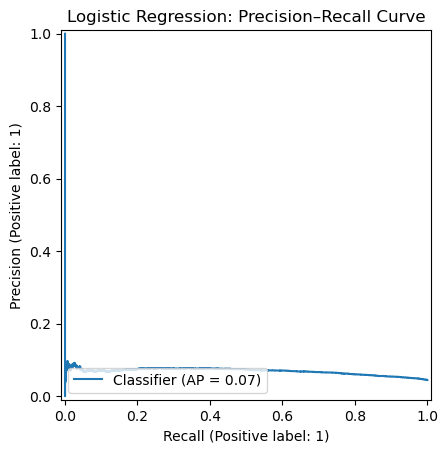

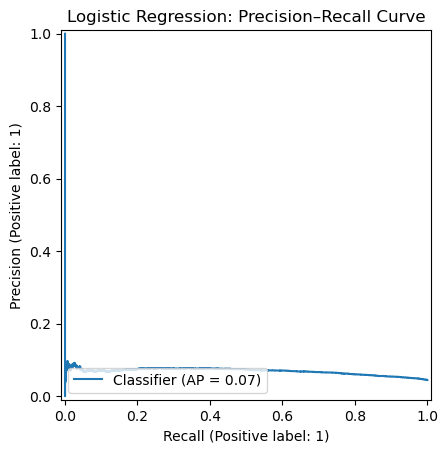

In [98]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Logistic Regression: Precision–Recall Curve")
plt.show()

In [99]:
yearly_performance = (
    modeling_data.groupby("purchase_year")
    .agg(
        total_orders=("late_delivery", "size"),
        late_orders=("late_delivery", "sum"),
        late_rate=("late_delivery", "mean")
    )
)

yearly_performance["late_rate_pct"] = (
    yearly_performance["late_rate"] * 100
).round(2)

display(yearly_performance)

,total_orders,late_orders,late_rate,late_rate_pct
purchase_year,,,,
2016,267,3,0.011236,1.12
2017,43412,2453,0.056505,5.65
2018,52777,4078,0.077269,7.73


,total_orders,late_orders,late_rate,late_rate_pct
purchase_year,,,,
2016,267,3,0.011236,1.12
2017,43412,2453,0.056505,5.65
2018,52777,4078,0.077269,7.73


In [100]:
modeling_data["purchase_year_month"] = (
    modeling_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

print("Unique year-month periods:",
      modeling_data["purchase_year_month"].nunique())

display(
    modeling_data.groupby("purchase_year_month", observed=True)
    .agg(
        total_orders=("late_delivery", "size"),
        late_orders=("late_delivery", "sum"),
        late_rate=("late_delivery", "mean")
    )
    .assign(
        late_rate_pct=lambda df: (df["late_rate"] * 100).round(2)
    )
)

Unique year-month periods: 23


,total_orders,late_orders,late_rate,late_rate_pct
purchase_year_month,,,,
2016-09,1,1,1.000000,100.00
2016-10,265,2,0.007547,0.75
2016-12,1,0,0.000000,0.00
2017-01,748,22,0.029412,2.94
2017-02,1641,49,0.029860,2.99
2017-03,2546,116,0.045562,4.56
2017-04,2303,151,0.065567,6.56
2017-05,3545,106,0.029901,2.99
2017-06,3135,95,0.030303,3.03


Unique year-month periods: 23


,total_orders,late_orders,late_rate,late_rate_pct
purchase_year_month,,,,
2016-09,1,1,1.000000,100.00
2016-10,265,2,0.007547,0.75
2016-12,1,0,0.000000,0.00
2017-01,748,22,0.029412,2.94
2017-02,1641,49,0.029860,2.99
2017-03,2546,116,0.045562,4.56
2017-04,2303,151,0.065567,6.56
2017-05,3545,106,0.029901,2.99
2017-06,3135,95,0.030303,3.03


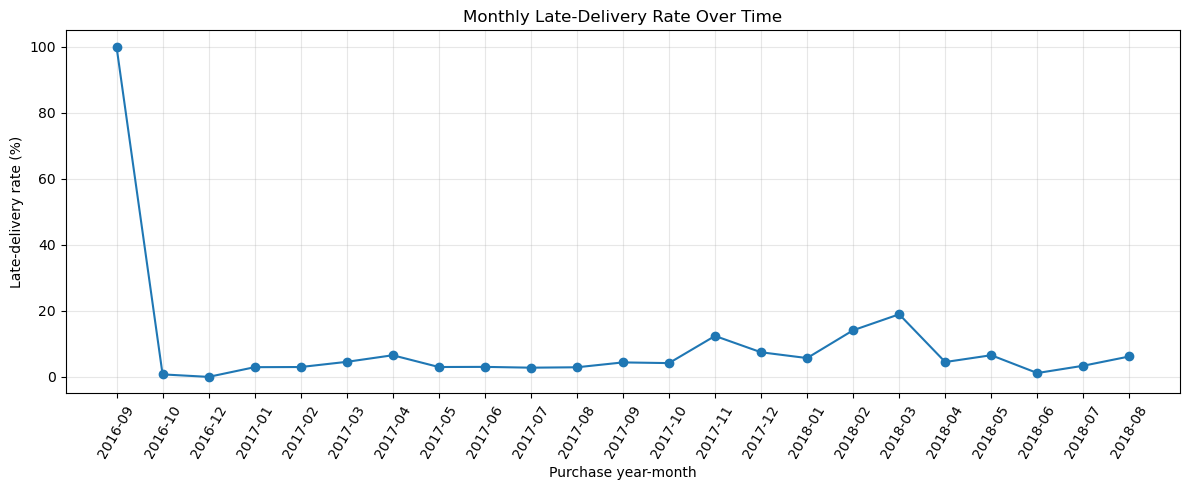

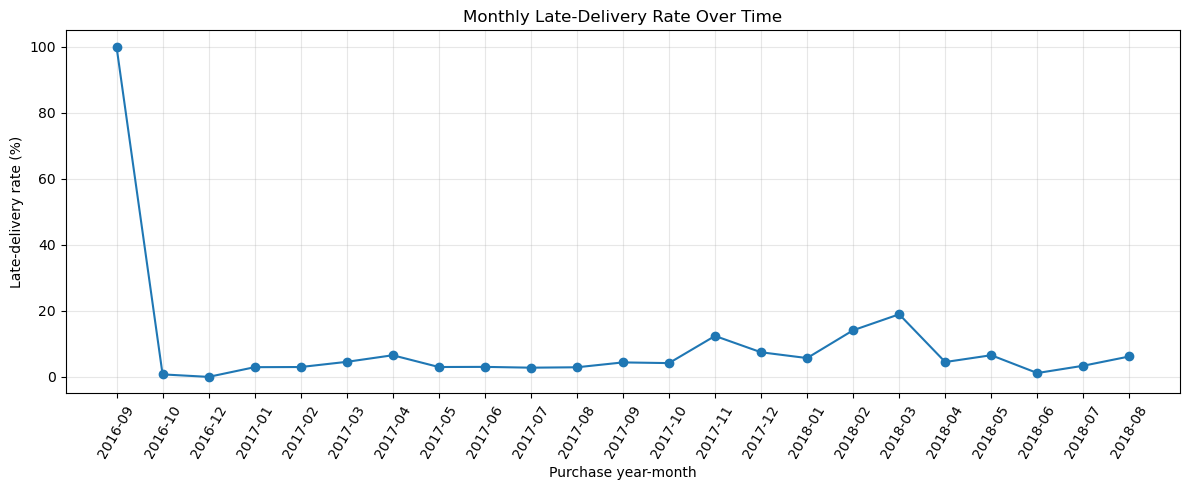

In [101]:
monthly_stats = (
    modeling_data.groupby("purchase_year_month")
    .agg(
        total_orders=("late_delivery", "size"),
        late_rate=("late_delivery", "mean")
    )
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_stats.index,
    monthly_stats["late_rate"] * 100,
    marker="o"
)
plt.xticks(rotation=60)
plt.xlabel("Purchase year-month")
plt.ylabel("Late-delivery rate (%)")
plt.title("Monthly Late-Delivery Rate Over Time")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [102]:
modeling_data["days_since_start"] = (
    modeling_data["order_purchase_timestamp"].dt.normalize()
    - modeling_data["order_purchase_timestamp"].min().normalize()
).dt.days

display(
    modeling_data[
        ["order_purchase_timestamp", "days_since_start"]
    ].head()
)

,order_purchase_timestamp,days_since_start
0,2017-10-02 10:56:33,382
1,2018-07-24 20:41:37,677
2,2018-08-08 08:38:49,692
3,2017-11-18 19:28:06,429
4,2018-02-13 21:18:39,516


In [103]:
time_correlation = modeling_data[
    ["days_since_start", "late_delivery"]
].corr().iloc[0, 1]

print(f"Correlation with late delivery: {time_correlation:.4f}")

Correlation with late delivery: 0.0319


In [104]:
print("Training period:")
print("Minimum day:", modeling_data.loc[train_mask, "days_since_start"].min())
print("Maximum day:", modeling_data.loc[train_mask, "days_since_start"].max())

print("\nTest period:")
print("Minimum day:", modeling_data.loc[test_mask, "days_since_start"].min())
print("Maximum day:", modeling_data.loc[test_mask, "days_since_start"].max())

Training period:
Minimum day: 0
Maximum day: 562

Test period:
Minimum day: 563
Maximum day: 713


In [105]:
period_comparison = pd.DataFrame({
    "period": ["Training", "Test"],
    "orders": [len(y_train), len(y_test)],
    "late_orders": [int(y_train.sum()), int(y_test.sum())],
    "late_rate_pct": [
        round(y_train.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})

display(period_comparison)

,period,orders,late_orders,late_rate_pct
0,Training,64306,5113,7.95
1,Test,32150,1421,4.42


In [106]:
monthly_validation = (
    modeling_data.groupby("purchase_year_month")
    .agg(
        orders=("late_delivery", "size"),
        late_orders=("late_delivery", "sum"),
        late_rate=("late_delivery", "mean")
    )
)

monthly_validation["late_rate_pct"] = (
    monthly_validation["late_rate"] * 100
).round(2)

display(monthly_validation)

,orders,late_orders,late_rate,late_rate_pct
purchase_year_month,,,,
2016-09,1,1,1.000000,100.00
2016-10,265,2,0.007547,0.75
2016-12,1,0,0.000000,0.00
2017-01,748,22,0.029412,2.94
2017-02,1641,49,0.029860,2.99
2017-03,2546,116,0.045562,4.56
2017-04,2303,151,0.065567,6.56
2017-05,3545,106,0.029901,2.99
2017-06,3135,95,0.030303,3.03


In [107]:
dates = modeling_data["order_purchase_timestamp"]

train_mask_new = dates < "2018-01-01"

validation_mask = (
    (dates >= "2018-01-01") &
    (dates < "2018-05-01")
)

final_mask = dates >= "2018-05-01"

for name, mask in [
    ("Training", train_mask_new),
    ("Validation", validation_mask),
    ("Final holdout", final_mask)
]:
    subset = modeling_data.loc[mask, "late_delivery"]

    print(
        f"{name}: {len(subset):,} orders | "
        f"{subset.sum():,} late | "
        f"Late rate: {subset.mean() * 100:.2f}%"
    )


Training: 43,679 orders | 2,456 late | Late rate: 5.62%
Validation: 27,425 orders | 2,963 late | Late rate: 10.80%
Final holdout: 25,352 orders | 1,115 late | Late rate: 4.40%


In [108]:
X_train_new = modeling_data.loc[
    train_mask_new, candidate_features
].copy()

y_train_new = modeling_data.loc[
    train_mask_new, "late_delivery"
].copy()

X_val = modeling_data.loc[
    validation_mask, candidate_features
].copy()

y_val = modeling_data.loc[
    validation_mask, "late_delivery"
].copy()

print("Training:", X_train_new.shape, y_train_new.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Training late rate:", round(y_train_new.mean() * 100, 2), "%")
print("Validation late rate:", round(y_val.mean() * 100, 2), "%")

Training: (43679, 11) (43679,)
Validation: (27425, 11) (27425,)
Training late rate: 5.62 %
Validation late rate: 10.8 %


In [109]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

scaler_new = StandardScaler()

X_train_new_scaled = scaler_new.fit_transform(X_train_new)
X_val_scaled = scaler_new.transform(X_val)

logistic_new = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_new.fit(X_train_new_scaled, y_train_new)

val_prob = logistic_new.predict_proba(X_val_scaled)[:, 1]

val_ap = average_precision_score(y_val, val_prob)

print(f"Validation PR-AUC (Average Precision): {val_ap:.4f}")
print(f"Validation late-delivery rate: {y_val.mean():.4f}")

Validation PR-AUC (Average Precision): 0.1316
Validation late-delivery rate: 0.1080


In [110]:
from sklearn.metrics import average_precision_score
import numpy as np

baseline_val_prob = np.full(
    len(y_val),
    y_train_new.mean()
)

baseline_val_ap = average_precision_score(
    y_val,
    baseline_val_prob
)

print(f"Baseline validation AP: {baseline_val_ap:.4f}")
print(f"Logistic Regression AP: {val_ap:.4f}")
print(f"Absolute improvement: {val_ap - baseline_val_ap:.4f}")

Baseline validation AP: 0.1080
Logistic Regression AP: 0.1316
Absolute improvement: 0.0235


In [111]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

rf_new = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_new.fit(X_train_new, y_train_new)

rf_val_prob = rf_new.predict_proba(X_val)[:, 1]

rf_val_ap = average_precision_score(
    y_val,
    rf_val_prob
)

print(f"Logistic Regression validation AP: {val_ap:.4f}")
print(f"Random Forest validation AP: {rf_val_ap:.4f}")
print(f"Baseline validation AP: {baseline_val_ap:.4f}")

Logistic Regression validation AP: 0.1316
Random Forest validation AP: 0.1147
Baseline validation AP: 0.1080


In [112]:
coefficient_table = pd.DataFrame({
    "feature": candidate_features,
    "coefficient": logistic_new.coef_[0]
})

coefficient_table["absolute_coefficient"] = (
    coefficient_table["coefficient"].abs()
)

display(
    coefficient_table.sort_values(
        "absolute_coefficient",
        ascending=False
    ).reset_index(drop=True)
)

,feature,coefficient,absolute_coefficient
0,purchase_month,0.373165,0.373165
1,total_freight,0.250602,0.250602
2,approval_delay_hours,0.178868,0.178868
3,seller_count,-0.159177,0.159177
4,total_items,-0.133328,0.133328
5,promised_delivery_days,-0.097814,0.097814
6,purchase_day_of_week,-0.090125,0.090125
7,approval_day_of_week,0.054976,0.054976
8,approval_hour,0.042442,0.042442
9,total_price,0.022807,0.022807


In [113]:
import numpy as np

modeling_data["month_sin"] = np.sin(
    2 * np.pi * modeling_data["purchase_month"] / 12
)

modeling_data["month_cos"] = np.cos(
    2 * np.pi * modeling_data["purchase_month"] / 12
)

display(
    modeling_data[
        ["purchase_month", "month_sin", "month_cos"]
    ].head()
)

,purchase_month,month_sin,month_cos
0,10,-0.866025,0.500000
1,7,-0.500000,-0.866025
2,8,-0.866025,-0.500000
3,11,-0.500000,0.866025
4,2,0.866025,0.500000


In [114]:
cyclical_features = [
    feature for feature in candidate_features
    if feature != "purchase_month"
] + ["month_sin", "month_cos"]

print("Original feature count:", len(candidate_features))
print("New feature count:", len(cyclical_features))
print("\nNew feature list:")

for feature in cyclical_features:
    print("-", feature)

Original feature count: 11
New feature count: 12

New feature list:
- total_items
- total_price
- total_freight
- seller_count
- promised_delivery_days
- purchase_day_of_week
- purchase_hour
- approval_day_of_week
- approval_hour
- approval_delay_hours
- month_sin
- month_cos


In [115]:
X_train_cyc = modeling_data.loc[
    train_mask_new, cyclical_features
].copy()

X_val_cyc = modeling_data.loc[
    validation_mask, cyclical_features
].copy()

scaler_cyc = StandardScaler()

X_train_cyc_scaled = scaler_cyc.fit_transform(X_train_cyc)
X_val_cyc_scaled = scaler_cyc.transform(X_val_cyc)

logistic_cyc = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_cyc.fit(X_train_cyc_scaled, y_train_new)

cyc_val_prob = logistic_cyc.predict_proba(X_val_cyc_scaled)[:, 1]

cyc_val_ap = average_precision_score(y_val, cyc_val_prob)

print(f"Original Logistic Regression AP: {val_ap:.4f}")
print(f"Cyclical month encoding AP:      {cyc_val_ap:.4f}")
print(f"Baseline AP:                     {baseline_val_ap:.4f}")
print(f"AP change:                       {cyc_val_ap - val_ap:+.4f}")


Original Logistic Regression AP: 0.1316
Cyclical month encoding AP:      0.1254
Baseline AP:                     0.1080
AP change:                       -0.0061


In [116]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

val_pred_05 = (val_prob >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val, val_pred_05, labels=[0, 1]
).ravel()

print("Threshold: 0.50")
print("Orders flagged as late:", int(val_pred_05.sum()))
print("True positives:", tp)
print("False positives:", fp)
print("False negatives:", fn)
print("Precision:", round(precision_score(y_val, val_pred_05, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, val_pred_05, zero_division=0), 4))

Threshold: 0.50
Orders flagged as late: 783
True positives: 119
False positives: 664
False negatives: 2844
Precision: 0.152
Recall: 0.0402


In [117]:
threshold = 0.20

val_pred_020 = (val_prob >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val, val_pred_020, labels=[0, 1]
).ravel()

print(f"Threshold: {threshold:.2f}")
print("Orders flagged:", int(val_pred_020.sum()))
print("True positives:", tp)
print("False positives:", fp)
print("False negatives:", fn)
print(
    "Precision:",
    round(precision_score(y_val, val_pred_020, zero_division=0), 4)
)
print(
    "Recall:",
    round(recall_score(y_val, val_pred_020, zero_division=0), 4)
)

Threshold: 0.20
Orders flagged: 27003
True positives: 2957
False positives: 24046
False negatives: 6
Precision: 0.1095
Recall: 0.998


In [118]:
threshold_results = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "orders_flagged": int(predictions.sum()),
        "flagged_pct": round(predictions.mean() * 100, 2),
        "precision": round(
            precision_score(y_val, predictions, zero_division=0), 4
        ),
        "recall": round(
            recall_score(y_val, predictions, zero_division=0), 4
        )
    })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table)

,threshold,orders_flagged,flagged_pct,precision,recall
0,0.10,27217,99.24,0.1088,0.9997
1,0.15,27077,98.73,0.1093,0.9987
2,0.20,27003,98.46,0.1095,0.9980
3,0.25,25224,91.97,0.1145,0.9750
4,0.30,16698,60.89,0.1259,0.7098
5,0.35,7319,26.69,0.1267,0.3129
6,0.40,3089,11.26,0.1395,0.1455
7,0.45,1430,5.21,0.1462,0.0705
8,0.50,783,2.86,0.1520,0.0402


In [119]:
review_fraction = 0.10

risk_cutoff = np.quantile(
    val_prob,
    1 - review_fraction
)

top_risk_pred = (val_prob >= risk_cutoff).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val, top_risk_pred, labels=[0, 1]
).ravel()

print(f"Risk score cutoff: {risk_cutoff:.4f}")
print("Orders flagged:", int(top_risk_pred.sum()))
print("Flagged percentage:", round(top_risk_pred.mean() * 100, 2))
print("Precision:", round(precision_score(y_val, top_risk_pred), 4))
print("Recall:", round(recall_score(y_val, top_risk_pred), 4))

Risk score cutoff: 0.4073
Orders flagged: 2743
Flagged percentage: 10.0
Precision: 0.1425
Recall: 0.132


In [120]:
review_results = []

for fraction in [0.05, 0.10, 0.20]:
    cutoff = np.quantile(val_prob, 1 - fraction)
    predictions = (val_prob >= cutoff).astype(int)

    flagged = int(predictions.sum())
    true_positives = int(
        ((predictions == 1) & (y_val.to_numpy() == 1)).sum()
    )

    review_results.append({
        "review_capacity_pct": fraction * 100,
        "orders_flagged": flagged,
        "late_orders_found": true_positives,
        "precision": true_positives / flagged,
        "recall": true_positives / int(y_val.sum()),
        "random_review_expected_recall_pct": fraction * 100
    })

review_comparison = pd.DataFrame(review_results)

display(review_comparison.round(4))

,review_capacity_pct,orders_flagged,late_orders_found,precision,recall,random_review_expected_recall_pct
0,5.0,1372,199,0.1450,0.0672,5.0
1,10.0,2743,391,0.1425,0.1320,10.0
2,20.0,5485,726,0.1324,0.2450,20.0


In [121]:
print(
    "Mean predicted score:",
    round(val_prob.mean(), 4)
)

print(
    "Actual validation late rate:",
    round(y_val.mean(), 4)
)

Mean predicted score: 0.3247
Actual validation late rate: 0.108


In [122]:
calibration_data = pd.DataFrame({
    "predicted_score": val_prob,
    "actual_late": y_val.to_numpy()
})

calibration_data["risk_group"] = pd.qcut(
    calibration_data["predicted_score"],
    q=10,
    duplicates="drop"
)

calibration_table = (
    calibration_data.groupby("risk_group", observed=True)
    .agg(
        orders=("actual_late", "size"),
        mean_predicted_score=("predicted_score", "mean"),
        actual_late_rate=("actual_late", "mean")
    )
)

calibration_table["mean_predicted_pct"] = (
    calibration_table["mean_predicted_score"] * 100
).round(2)

calibration_table["actual_late_pct"] = (
    calibration_table["actual_late_rate"] * 100
).round(2)

display(
    calibration_table[
        ["orders", "mean_predicted_pct", "actual_late_pct"]
    ]
)

,orders,mean_predicted_pct,actual_late_pct
risk_group,,,
"(-7.000000000000062e-06, 0.254]",2743,22.09,3.79
"(0.254, 0.271]",2742,26.30,6.75
"(0.271, 0.286]",2743,27.84,9.52
"(0.286, 0.301]",2742,29.36,12.58
"(0.301, 0.316]",2743,30.89,13.16
"(0.316, 0.33]",2742,32.31,13.02
"(0.33, 0.344]",2742,33.67,11.96
"(0.344, 0.365]",2743,35.36,10.79
"(0.365, 0.407]",2742,38.36,12.22


In [123]:
from sklearn.metrics import roc_auc_score

val_roc_auc = roc_auc_score(y_val, val_prob)

print(f"Validation ROC-AUC: {val_roc_auc:.4f}")
print(f"Validation PR-AUC:  {val_ap:.4f}")

Validation ROC-AUC: 0.5718
Validation PR-AUC:  0.1316


In [124]:
print("Unique sellers:", items["seller_id"].nunique())
print("Order-item records:", len(items))
print("Unique orders with item records:", items["order_id"].nunique())

display(
    items.groupby("seller_id")
    .agg(
        order_items=("order_id", "size"),
        unique_orders=("order_id", "nunique")
    )
    .describe()
)

Unique sellers: 3095
Order-item records: 112650
Unique orders with item records: 98666


,order_items,unique_orders
count,3095.000000,3095.000000
mean,36.397415,32.313409
std,119.193461,105.139763
min,1.000000,1.000000
25%,2.000000,2.000000
50%,8.000000,6.000000
75%,24.000000,21.500000
max,2033.000000,1854.000000


In [125]:
seller_history = (
    modeling_data[["order_id", "late_delivery"]]
    .merge(
        items[["order_id", "seller_id"]].drop_duplicates(),
        on="order_id",
        how="inner"
    )
    .groupby("seller_id")
    .agg(
        historical_orders=("order_id", "nunique"),
        late_orders=("late_delivery", "sum"),
        late_rate=("late_delivery", "mean")
    )
)

display(seller_history["historical_orders"].describe())

print(
    "\nSellers with fewer than 5 eligible orders:",
    int((seller_history["historical_orders"] < 5).sum())
)

print(
    "Sellers with at least 20 eligible orders:",
    int((seller_history["historical_orders"] >= 20).sum())
)

count    2970.000000
mean       32.928283
std       105.388261
min         1.000000
25%         2.000000
50%         7.000000
75%        22.000000
max      1819.000000
Name: historical_orders, dtype: float64


Sellers with fewer than 5 eligible orders: 1204
Sellers with at least 20 eligible orders: 804


In [126]:
print("Purchase timestamp:")
print(modeling_data["order_purchase_timestamp"].min())
print(modeling_data["order_purchase_timestamp"].max())

print("\nDelivery timestamp:")
print(modeling_data["order_delivered_customer_date"].min())
print(modeling_data["order_delivered_customer_date"].max())

print("\nMissing delivery timestamps:")
print(modeling_data["order_delivered_customer_date"].isna().sum())

Purchase timestamp:
2016-09-15 12:16:38
2018-08-29 15:00:37

Delivery timestamp:
2016-10-11 13:46:32
2018-10-17 13:22:46

Missing delivery timestamps:
0


In [127]:
delivery_history = (
    modeling_data["order_delivered_customer_date"]
    - modeling_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

display(delivery_history.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

count    96456.000000
mean        12.558106
std          9.546797
min          0.533414
25%          6.765550
50%         10.216267
75%         15.720229
90%         23.097159
95%         29.274433
99%         46.051075
max        209.628611
dtype: float64

In [128]:

# Prepare order-level delivery outcomes and seller mapping

seller_orders = (
    modeling_data[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "late_delivery"
        ]
    ]
    .merge(
        items[["order_id", "seller_id"]].drop_duplicates(),
        on="order_id",
        how="inner",
        validate="one_to_many"
    )
    .sort_values("order_purchase_timestamp")
    .reset_index(drop=True)
)

print("Seller-order records:", seller_orders.shape[0])
print("Unique sellers:", seller_orders["seller_id"].nunique())
print(
    "Missing seller IDs:",
    seller_orders["seller_id"].isna().sum()
)

display(seller_orders.head())


Seller-order records: 97797
Unique sellers: 2970
Missing seller IDs: 0


,order_id,order_purchase_timestamp,order_delivered_customer_date,late_delivery,seller_id
0,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,2016-11-09 07:47:38,1,ecccfa2bb93b34a3bf033cc5d1dcdc69
1,3b697a20d9e427646d92567910af6d57,2016-10-03 09:44:50,2016-10-26 14:02:13,0,522620dcb18a6b31cd7bdf73665113a9
2,be5bc2f0da14d8071e2d45451ad119d9,2016-10-03 16:56:50,2016-10-27 18:19:38,0,f09b760d23495ac9a7e00d29b769007c
3,a41c8759fbe7aab36ea07e038b2d4465,2016-10-03 21:13:36,2016-11-03 10:58:07,0,45d33f715e24d15a6ccf5c17b3a23e3c
4,d207cc272675637bfed0062edffd0818,2016-10-03 22:06:03,2016-10-31 11:07:42,0,cca3071e3e9bb7d12640c9fbe2301306


In [129]:

# Keep only the columns needed for historical seller reliability
seller_history_events = seller_orders[
    [
        "seller_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "late_delivery"
    ]
].copy()

# The outcome becomes available when the order is delivered
seller_history_events = seller_history_events.sort_values(
    "order_delivered_customer_date"
).reset_index(drop=True)

print("Historical events:", len(seller_history_events))
print(
    "Events with delivery before purchase:",
    (
        seller_history_events["order_delivered_customer_date"]
        < seller_history_events["order_purchase_timestamp"]
    ).sum()
)

display(seller_history_events.head())


Historical events: 97797
Events with delivery before purchase: 0


,seller_id,order_purchase_timestamp,order_delivered_customer_date,late_delivery
0,939f6e231201f26803cb5c3a3d2940b3,2016-10-04 13:11:29,2016-10-11 13:46:32,0
1,df560393f3a51e74553ab94004ba5c87,2016-10-04 14:13:22,2016-10-11 14:46:49,0
2,2138ccb85b11a4ec1e37afbd1c8eda1f,2016-10-04 19:30:28,2016-10-13 03:10:34,0
3,62c50c1af4dfdc4149d25c5222043d39,2016-10-05 11:08:46,2016-10-13 07:45:48,0
4,ed859002ad59dbf8cf3602696a6c3000,2016-10-05 15:08:00,2016-10-13 15:44:27,0


In [130]:

# Training period: orders purchased before 1 January 2018
train_end = pd.Timestamp("2018-01-01")

train_orders = modeling_data[
    modeling_data["order_purchase_timestamp"] < train_end
].copy()

prior_late_rate = train_orders["late_delivery"].mean()

print("Training orders:", len(train_orders))
print("Training late-delivery rate:", round(prior_late_rate, 4))
print("Training late-delivery rate (%):", round(prior_late_rate * 100, 2))


Training orders: 43679
Training late-delivery rate: 0.0562
Training late-delivery rate (%): 5.62


In [131]:

import numpy as np
import pandas as pd

# One row per seller-order relationship, with outcome availability time
events = seller_orders[
    [
        "order_id",
        "seller_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "late_delivery"
    ]
].copy()

# Each historical outcome becomes available at delivery time
events = events.rename(
    columns={
        "order_purchase_timestamp": "historical_purchase_time",
        "order_delivered_customer_date": "outcome_available_time",
        "late_delivery": "historical_late"
    }
)

# Current orders: one row per order-seller relationship
current = seller_orders[
    ["order_id", "seller_id", "order_purchase_timestamp"]
].rename(
    columns={"order_purchase_timestamp": "prediction_time"}
).copy()

# Candidate history must have been delivered before the current purchase
history_candidates = current.merge(
    events[["seller_id", "outcome_available_time", "historical_late"]],
    on="seller_id",
    how="left"
)

history_candidates = history_candidates[
    history_candidates["outcome_available_time"]
    < history_candidates["prediction_time"]
]

# Aggregate only outcomes already available at prediction time
seller_history_features = (
    history_candidates
    .groupby(["order_id", "seller_id"], as_index=False)
    .agg(
        prior_seller_orders=("historical_late", "size"),
        prior_seller_late_orders=("historical_late", "sum")
    )
)

# Attach counts to every current order-seller pair
seller_features = current[
    ["order_id", "seller_id"]
].merge(
    seller_history_features,
    on=["order_id", "seller_id"],
    how="left",
    validate="one_to_one"
)

seller_features[
    ["prior_seller_orders", "prior_seller_late_orders"]
] = seller_features[
    ["prior_seller_orders", "prior_seller_late_orders"]
].fillna(0)

# Smooth using the training-period prior
alpha = 10

seller_features["seller_historical_late_rate"] = (
    seller_features["prior_seller_late_orders"]
    + alpha * prior_late_rate
) / (
    seller_features["prior_seller_orders"] + alpha
)

print("Seller feature rows:", len(seller_features))
print(
    "Pairs with no prior completed orders:",
    int((seller_features["prior_seller_orders"] == 0).sum())
)
print(
    "Missing reliability scores:",
    seller_features["seller_historical_late_rate"].isna().sum()
)

display(seller_features.head())


Seller feature rows: 97797
Pairs with no prior completed orders: 5314
Missing reliability scores: 0


,order_id,seller_id,prior_seller_orders,prior_seller_late_orders,seller_historical_late_rate
0,bfbd0f9bdef84302105ad712db648a6c,ecccfa2bb93b34a3bf033cc5d1dcdc69,0.0,0.0,0.056228
1,3b697a20d9e427646d92567910af6d57,522620dcb18a6b31cd7bdf73665113a9,0.0,0.0,0.056228
2,be5bc2f0da14d8071e2d45451ad119d9,f09b760d23495ac9a7e00d29b769007c,0.0,0.0,0.056228
3,a41c8759fbe7aab36ea07e038b2d4465,45d33f715e24d15a6ccf5c17b3a23e3c,0.0,0.0,0.056228
4,d207cc272675637bfed0062edffd0818,cca3071e3e9bb7d12640c9fbe2301306,0.0,0.0,0.056228


In [132]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Validation Average Precision": [
        0.1080,
        0.1316,
        0.1147
    ]
})

model_comparison["Improvement over Baseline (%)"] = (
    (model_comparison["Validation Average Precision"] / 0.1080) - 1
) * 100

display(
    model_comparison.round(2)
)

,Model,Validation Average Precision,Improvement over Baseline (%)
0,Baseline,0.11,0.00
1,Logistic Regression,0.13,21.85
2,Random Forest,0.11,6.20


In [133]:
print("Logistic Regression model exists:", "logistic_new" in globals())
print("Scaler exists:", "scaler_new" in globals())
print("Final holdout features exist:", "final_mask" in globals())

if "final_mask" in globals():
    print("Final holdout orders:", int(final_mask.sum()))

Logistic Regression model exists: True
Scaler exists: True
Final holdout features exist: True
Final holdout orders: 25352


In [134]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Prepare the untouched final holdout
X_final = modeling_data.loc[final_mask, candidate_features].copy()
y_final = modeling_data.loc[final_mask, "late_delivery"].copy()

# Apply the scaler fitted on training data only
X_final_scaled = scaler_new.transform(X_final)

# Generate predictions and risk scores
final_prob = logistic_new.predict_proba(X_final_scaled)[:, 1]
final_pred = (final_prob >= 0.5).astype(int)

# Evaluate once on the final holdout
print("Final holdout orders:", len(y_final))
print("Actual late-delivery rate:", round(y_final.mean(), 4))
print("Average Precision:", round(average_precision_score(y_final, final_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_final, final_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_final, final_pred))

print("\nClassification Report:")
print(classification_report(
    y_final,
    final_pred,
    target_names=["On time", "Late"],
    zero_division=0
))

Final holdout orders: 25352
Actual late-delivery rate: 0.044
Average Precision: 0.0572
ROC-AUC: 0.5882

Confusion Matrix:
[[19275  4962]
 [  778   337]]

Classification Report:
              precision    recall  f1-score   support

     On time       0.96      0.80      0.87     24237
        Late       0.06      0.30      0.11      1115

    accuracy                           0.77     25352
   macro avg       0.51      0.55      0.49     25352
weighted avg       0.92      0.77      0.84     25352



In [135]:
from pathlib import Path
import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(logistic_new, MODEL_DIR / "logistic_model.joblib")
joblib.dump(scaler_new, MODEL_DIR / "scaler.joblib")
joblib.dump(candidate_features, MODEL_DIR / "feature_names.joblib")

print("Model saved:", (MODEL_DIR / "logistic_model.joblib").exists())
print("Scaler saved:", (MODEL_DIR / "scaler.joblib").exists())
print("Feature list saved:", (MODEL_DIR / "feature_names.joblib").exists())

Model saved: True
Scaler saved: True
Feature list saved: True
